# Software Engineering for AI Developers: OOP and SOLID Principles

> **Who is this for:** you can write Python functions and simple classes, and now your AI code (model wrappers, data pipelines, LLM clients) is growing past one notebook. You want it to be easy to test, change and share with a team. University students revising object-oriented design for exams or interviews are also welcome.
>
> **What you will learn:**
> - classes, objects, encapsulation (properties, name mangling, naming conventions)
> - inheritance vs. composition (with a refactoring), polymorphism, duck typing, abstract base classes vs. `typing.Protocol`
> - the dunder methods that matter for AI wrappers, dataclasses (`frozen`, `slots`), enums
> - class methods vs. static methods, the method resolution order (MRO), `super()` and diamond inheritance (with C3 implemented from scratch)
> - the five **SOLID** principles, each with a "bad" and a refactored "good" version on AI code
> - DRY, KISS, YAGNI, the law of Demeter, common code smells (and a tiny smell detector)
> - reading and drawing a UML class diagram
>
> **Prerequisites:** [01_Python/01_basic.ipynb](../01_Python/01_basic.ipynb) (functions, classes). Helpful: [01_Python/02_industrial.ipynb](../01_Python/02_industrial.ipynb), [01_Python/03_advanced.ipynb](../01_Python/03_advanced.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no network. Uses the Python standard library, numpy, pandas, scikit-learn and matplotlib.
>
> **Optional track:** part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

Writing a big program is like building with LEGO: if every brick has a clear shape and one clear job, you can swap, reuse and fix bricks without knocking the whole castle down. In Python, a **class** is the instruction sheet for one kind of brick, and an **object** is an actual brick built from that sheet. **Object-oriented programming (OOP)** is the habit of organising code into such bricks, and the five **SOLID** principles are rules of thumb that keep them small, swappable and honest about what they do. Think of phone chargers: because the plug shape is a shared standard, any charger works with any phone that has that socket. That shared "shape" is what programmers call an **interface**. Or think of a restaurant kitchen: the chef doesn't also take orders and wash dishes, so when the dishwasher is off sick, the cooking still works. Giving each part one job is the first SOLID rule.

**Tiny example.** A class `Dog` stores a name and has a method `bark()`. `rex = Dog("Rex")` and `fido = Dog("Fido")` are two objects made from the same class: `rex.bark()` prints "Rex says woof!" and `fido.bark()` prints "Fido says woof!". Same code, different data. In AI code, swap `Dog` for `SentimentModel` and `bark()` for `predict()`.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Class and object | a recipe vs. the actual cake baked from it | `LogisticRegression` (the class) vs. your trained model (an object) |
| Composition | build things from parts, not from family trees | a chatbot that *has* an LLM client, a cache and a retry policy |
| SOLID | five rules that keep code parts small and swappable | switching LLM provider without rewriting the whole app |

### How this notebook fits with the rest of the repo

Some of these topics already appear briefly elsewhere. This notebook goes **deeper** and focuses on **design decisions**, not syntax.

| Already covered | Where | What this notebook adds |
|---|---|---|
| Dataclass basics (`frozen`, `order`, `asdict`) | [02_industrial §9](../01_Python/02_industrial.ipynb) | `slots`, the `__eq__`/`__hash__` contract, validation in `__post_init__`, measured memory savings |
| `Protocol` basics | [03_advanced §3](../01_Python/03_advanced.ipynb) | when to pick an ABC vs. a Protocol, the limits of `runtime_checkable`, protocols for interface segregation |
| Operator overloading | [03_advanced §6](../01_Python/03_advanced.ipynb) | the dunders an AI wrapper needs, and the contracts they must keep |
| Context managers, decorators | [02_industrial §2-3](../01_Python/02_industrial.ipynb) | exception semantics of `__exit__`, `ExitStack` |
| Refactoring one messy script into a package | [01_Python/04](../01_Python/04_industry_from_notebook_to_production_code.ipynb) | the *principles* behind each refactoring step (SOLID, smells) |
| The notebook-to-production mindset | [22_ML_System_Design/07](../22_ML_System_Design/07_software_engineering_for_ml.ipynb) | object-level design of the pieces |

Design patterns (factory, adapter, strategy, observer, ...) get their own notebook: [02_design_patterns_for_ai_code.ipynb](02_design_patterns_for_ai_code.ipynb). Testing is in [03_testing_ai_code.ipynb](03_testing_ai_code.ipynb).

### Table of contents
1. Classes and objects
2. Encapsulation: conventions, name mangling, properties
3. Inheritance vs. composition (with a refactoring)
4. Polymorphism, duck typing, ABCs vs. Protocols
5. Dunder methods
6. Dataclasses and enums
7. Class methods vs. static methods
8. The MRO, `super()` and diamond inheritance
9. SOLID, one principle at a time
10. DRY, KISS, YAGNI and the law of Demeter
11. Code smells and how to fix them
12. UML class diagrams
13. How this connects to modern AI
14. Recap, practice problems, further reading

In [1]:
# Setup: everything this notebook needs. All of it is CPU-only and offline.
import sys, math, time, random, inspect, ast, io, os, tracemalloc   # standard library tools
from abc import ABC, abstractmethod                                  # abstract base classes
from collections import OrderedDict                                  # used in a practice problem
from contextlib import contextmanager, ExitStack                     # context-manager helpers
from dataclasses import dataclass, field, FrozenInstanceError, replace, asdict
from enum import Enum, StrEnum, auto                                 # enumerations
from typing import Protocol, runtime_checkable, Iterator, Sequence, Callable

import numpy as np                                                   # numerical arrays
import pandas as pd                                                  # tables for traces
import matplotlib.pyplot as plt                                      # the UML diagram

random.seed(42)                                                      # reproducible randomness
np.random.seed(42)
pd.set_option("display.width", 120)                                  # wide tables print on one line
print("Python", sys.version.split()[0])

Python 3.12.3


---
## 1. Classes and objects

> 💡 **In plain English:** a class is a blueprint, an object is one thing built from it, with its own data.

**Intuition.** A class is a cookie cutter; objects are the cookies. You write the cutter once, then stamp out as many cookies as you like, each with its own icing. In AI code, `SentimentModel` is the class, and each trained model (with its own vocabulary and weights) is an object.

**Definitions.**
- A **class** is a user-defined type: a bundle of data (attributes) and behaviour (methods).
- An **object** (or **instance**) is one value of that type, created by calling the class: `model = SentimentModel()`.
- An **instance attribute** belongs to one object (stored in `obj.__dict__`). A **class attribute** is stored on the class and shared by all instances.
- A **method** is a function defined in the class. Python passes the object as the first argument, called `self` by convention.
- `__init__` is the **initialiser**: it fills in a freshly created object. (The object itself is created by `__new__`, which you rarely touch.)

```
            class KeywordSentimentModel                  <- one blueprint
            |-- class attribute: labels = ("neg", "pos")    (shared)
            '-- methods: predict(), predict_one()
                       |  call the class to instantiate
             +---------+-------------+
          model_a                  model_b               <- two objects
          positive={"great"}       positive={"good","love"}
          n_predictions=0          n_predictions=0           (own __dict__ each)
```

In [2]:
class KeywordSentimentModel:
    """A tiny rule-based sentiment model: counts positive vs. negative keywords."""

    labels = ("neg", "pos")                       # class attribute: shared by every instance

    def __init__(self, positive, negative):
        self.positive = set(positive)             # instance attribute: this model's own words
        self.negative = set(negative)
        self.n_predictions = 0                    # per-object counter

    def predict_one(self, text):
        words = text.lower().split()              # naive tokenisation
        score = sum(w in self.positive for w in words) - sum(w in self.negative for w in words)
        self.n_predictions += 1                   # mutate this object's state only
        return self.labels[1] if score > 0 else self.labels[0]

    def predict(self, texts):
        return [self.predict_one(t) for t in texts]


model_a = KeywordSentimentModel(positive=["great"], negative=["awful"])
model_b = KeywordSentimentModel(positive=["good", "love"], negative=["bad"])

print(model_a.predict(["a great film", "awful plot"]))       # uses model_a's words
print(model_b.predict(["a great film", "i love it"]))         # same method, different data
print("model_a.__dict__ :", model_a.__dict__)                 # instance attributes live here
print("labels shared?   :", model_a.labels is model_b.labels) # class attribute: one object
print("type / isinstance:", type(model_a).__name__, isinstance(model_a, KeywordSentimentModel))

['pos', 'neg']
['neg', 'pos']
model_a.__dict__ : {'positive': {'great'}, 'negative': {'awful'}, 'n_predictions': 2}
labels shared?   : True
type / isinstance: KeywordSentimentModel True


**What just happened?** Both objects share the `predict` code and the `labels` tuple, but each has its own `positive`/`negative` sets and its own `n_predictions` counter. `"a great film"` is positive for `model_a` (it knows "great") but negative for `model_b` (it does not).

**Attribute lookup** `obj.x` checks the instance `__dict__` first, then the class, then the base classes in MRO order (section 8). Each step is a dictionary lookup, so it is **O(1) on average** per class searched.

> ⚠️ **Common mistake: a mutable class attribute.** A list defined at class level is shared by *all* instances. Below, two models "remember" each other's history.

In [3]:
class BuggyLogger:
    history = []                          # BUG: one list on the class, shared by all objects

    def log(self, msg):
        self.history.append(msg)          # appends to the shared class list


class FixedLogger:
    def __init__(self):
        self.history = []                 # FIX: a fresh list per object, created in __init__

    def log(self, msg):
        self.history.append(msg)


a, b = BuggyLogger(), BuggyLogger()
a.log("epoch 1 done")
print("buggy b.history:", b.history)      # b sees a's message!

a, b = FixedLogger(), FixedLogger()
a.log("epoch 1 done")
print("fixed b.history:", b.history)      # empty, as expected

buggy b.history: ['epoch 1 done']
fixed b.history: []


---
## 2. Encapsulation: conventions, name mangling, properties

> 💡 **In plain English:** hide the messy insides of an object and offer a small, safe set of buttons to the outside.

**Intuition.** A car exposes a steering wheel and pedals, not the fuel-injection timing. **Encapsulation** means an object hides its internal details and exposes a small, safe interface, so the internals can change without breaking the people who use it.

Python has no `private` keyword. It relies on **conventions** and two mechanisms:

| Spelling | Meaning | Enforced by Python? |
|---|---|---|
| `temperature` | public: part of the interface | - |
| `_api_key` | internal: "please don't touch from outside" | No, convention only (linters warn) |
| `__cache` (two leading underscores, at most one trailing) | **name mangling**: renamed to `_ClassName__cache` so subclasses can't clash with it by accident | Renamed, but still reachable; it is *not* security |
| `@property` | an attribute whose read/write runs code (validation, computed values) | Yes, the code always runs |

A **property** lets you start with a plain attribute and later add validation **without changing callers** (`cfg.temperature = 0.7` keeps working). This is why Python code rarely needs Java-style `get_temperature()` methods.

In [4]:
class GenerationConfig:
    """Sampling settings for an LLM call, with validation."""

    def __init__(self, temperature=0.7, max_tokens=256, api_key="sk-demo-123456"):
        self.temperature = temperature        # goes through the property setter below
        self.max_tokens = max_tokens
        self._api_key = api_key               # internal by convention
        self.__cache = {}                     # name-mangled to _GenerationConfig__cache

    @property
    def temperature(self):                    # read: cfg.temperature
        return self._temperature

    @temperature.setter
    def temperature(self, value):             # write: cfg.temperature = value
        if not 0.0 <= value <= 2.0:           # many LLM APIs accept 0..2 (some only 0..1)
            raise ValueError(f"temperature must be in [0, 2], got {value}")
        self._temperature = float(value)

    @property
    def is_deterministic(self):               # read-only computed property (no setter)
        return self._temperature == 0.0

    def __repr__(self):                       # never print secrets: mask the key
        return f"GenerationConfig(temperature={self.temperature}, max_tokens={self.max_tokens}, api_key='***')"


cfg = GenerationConfig()
cfg.temperature = 0.0                          # looks like an attribute, runs validation
print(cfg, "| deterministic:", cfg.is_deterministic)

try:
    cfg.temperature = 3.5                      # invalid: rejected
except ValueError as e:
    print("ValueError:", e)

try:
    cfg.is_deterministic = True                # no setter -> cannot assign
except AttributeError as e:
    print("AttributeError:", e)

print("stored attribute names:", sorted(vars(cfg)))

GenerationConfig(temperature=0.0, max_tokens=256, api_key='***') | deterministic: True
ValueError: temperature must be in [0, 2], got 3.5
AttributeError: property 'is_deterministic' of 'GenerationConfig' object has no setter
stored attribute names: ['_GenerationConfig__cache', '_api_key', '_temperature', 'max_tokens']


In [5]:
class CachedConfig(GenerationConfig):
    def __init__(self):
        super().__init__()
        self.__cache = "subclass cache"        # mangled to _CachedConfig__cache: no clash

c = CachedConfig()
print({k: v for k, v in vars(c).items() if "cache" in k})   # both caches exist side by side
print("still reachable from outside:", c._GenerationConfig__cache)  # mangling is not security

{'_GenerationConfig__cache': {}, '_CachedConfig__cache': 'subclass cache'}
still reachable from outside: {}


**What just happened?** The setter rejected `3.5`, and the read-only property refused assignment. `vars(cfg)` shows `_GenerationConfig__cache`: Python rewrote `self.__cache` inside the class body. The subclass's own `__cache` became `_CachedConfig__cache`, so the two never collide. That is the *only* purpose of name mangling.

> ⚠️ **Common mistake:** putting secrets in `__attr` and thinking they are private. Anyone can read `obj._Class__attr`. Keep secrets out of objects you log, and mask them in `__repr__` as above.
>
> 🎓 **Exam / interview tip:** "Does Python have private attributes?" Answer: no access control; `_x` is a convention, `__x` triggers name mangling to avoid subclass clashes, and `@property` gives controlled access (the *uniform access principle*: callers cannot tell a stored attribute from a computed one).

---
## 3. Inheritance vs. composition (with a refactoring)

> 💡 **In plain English:** prefer building an object out of smaller parts over creating long family trees of classes.

- **Inheritance** ("is-a"): `class B(A)` makes `B` a specialised `A`. `B` reuses `A`'s code and can override methods.
- **Composition** ("has-a"): an object *holds* other objects and delegates work to them.

The Gang of Four book (*Design Patterns*, 1994) put it as: **"Favor object composition over class inheritance."** Here is why, on a realistic problem.

**The problem.** We call an LLM provider. Sometimes we want **retries** (the network is flaky), sometimes a **cache** (the same prompt repeats), sometimes **logging**. With inheritance, every *combination* needs its own subclass:

```
                 BaseClient
       +-------------+-------------+
  RetryingClient  CachingClient  LoggingClient
       +------+------+      ...
  CachingRetryingClient  LoggingRetryingClient  LoggingCachingRetryingClient ...
```

With n independent features there are 2^n combinations (including "none"), so 2^n − 1 subclasses on top of the base. That is the **class explosion** smell.

In [6]:
# How many subclasses would inheritance need vs. how many parts composition needs?
rows = [{"features": n, "inheritance: subclasses for all combos (2^n - 1)": 2**n - 1,
         "composition: components": n} for n in range(1, 6)]
print(pd.DataFrame(rows).to_string(index=False))

 features  inheritance: subclasses for all combos (2^n - 1)  composition: components
        1                                                 1                        1
        2                                                 3                        2
        3                                                 7                        3
        4                                                15                        4
        5                                                31                        5


In [7]:
class FlakyFakeLLM:
    """A fake LLM provider: fails with a timeout every 2nd call, otherwise echoes."""
    def __init__(self):
        self.calls = 0
    def complete(self, prompt):
        self.calls += 1
        if self.calls % 2 == 1:                       # 1st, 3rd, 5th ... call times out
            raise TimeoutError("provider timed out")
        return f"answer to: {prompt}"

# ---- BAD: features glued on with inheritance --------------------------------
class RetryingClient(FlakyFakeLLM):
    def complete(self, prompt):
        for attempt in range(3):
            try:
                return super().complete(prompt)
            except TimeoutError:
                continue
        raise TimeoutError("gave up")

class CachingRetryingClient(RetryingClient):          # one more class per combination...
    def __init__(self):
        super().__init__()
        self.cache = {}
    def complete(self, prompt):
        if prompt not in self.cache:
            self.cache[prompt] = super().complete(prompt)
        return self.cache[prompt]
# ...and LoggingClient, LoggingRetryingClient, LoggingCachingClient, ... The provider is
# also hard-wired as the base class: switching provider means a new hierarchy.

bad = CachingRetryingClient()
print(bad.complete("hi"), bad.complete("hi"), "| provider calls:", bad.calls)

answer to: hi

 answer to: hi | provider calls: 2


In [8]:
# ---- GOOD: one service composed from independent, optional parts --------------
class ChatService:
    """Has-a client, has-a cache, has-a retry policy, has-a logger. Mix freely."""
    def __init__(self, client, cache=None, max_retries=0, log=None):
        self.client = client               # any object with .complete(prompt)
        self.cache = cache                 # any dict-like, or None for no caching
        self.max_retries = max_retries     # 0 = no retries
        self.log = log or (lambda msg: None)

    def complete(self, prompt):
        if self.cache is not None and prompt in self.cache:
            self.log(f"cache hit: {prompt!r}")
            return self.cache[prompt]
        for attempt in range(self.max_retries + 1):
            try:
                answer = self.client.complete(prompt)        # delegate to the component
                break
            except TimeoutError:
                self.log(f"attempt {attempt + 1} timed out")
        else:                                                 # loop ended without break
            raise TimeoutError(f"failed after {self.max_retries + 1} attempts")
        if self.cache is not None:
            self.cache[prompt] = answer
        return answer

events = []
svc = ChatService(FlakyFakeLLM(), cache={}, max_retries=2, log=events.append)
print(svc.complete("hi"), "|", svc.complete("hi"))
print("log:", events)
print("provider calls:", svc.client.calls)

plain = ChatService(FlakyFakeLLM())                          # no retries, no cache
try:
    plain.complete("hi")
except TimeoutError as e:
    print("without retries:", e)

answer to: hi | answer to: hi
log: ['attempt 1 timed out', "cache hit: 'hi'"]
provider calls: 2
without retries: failed after 1 attempts


**What just happened?** Both versions give the same answer, but the composed `ChatService` gets any combination of features from **one** class by passing different parts in. The first provider call timed out, the retry succeeded, and the second `"hi"` came from the cache (2 provider calls in total). Swapping the provider is now just passing another `client`; with inheritance it would mean a new class hierarchy.

| | Inheritance | Composition |
|---|---|---|
| Relationship | is-a | has-a |
| Coupling | tight: subclass depends on base internals | loose: depends only on the part's interface |
| Change at runtime? | no (fixed at class definition) | yes (pass a different part) |
| Combinations of features | class explosion (2^n − 1 subclasses) | n parts, combine freely |
| Good for | true subtypes, framework hooks (`nn.Module`, `BaseEstimator`), shallow (1-2 level) hierarchies | features that vary independently, swappable providers |

> 🎓 **Exam / interview tip:** "When would you still use inheritance?" When the subclass really *is* a substitutable kind of the base (it passes the Liskov test in section 9.3), or a framework asks you to subclass (PyTorch `nn.Module`, Keras `Callback`). Keep hierarchies shallow.

---
## 4. Polymorphism, duck typing, ABCs vs. Protocols

> 💡 **In plain English:** different objects can answer the same request in their own way, so one function works with all of them.

**Polymorphism** ("many shapes") means one piece of code works with objects of different types, because they all answer the same message. **Duck typing** is Python's version: *"if it walks like a duck and quacks like a duck, it is a duck."* Python does not check the type; it just calls the method and fails only if it is missing.

The `evaluate` function below only needs "something with `.predict(list_of_texts)`". Our keyword model, a constant baseline and a real scikit-learn `Pipeline` all qualify, with no shared base class.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

train_texts = ["great film", "loved it", "really good", "awful film", "bad plot", "hated it"]
train_labels = ["pos", "pos", "pos", "neg", "neg", "neg"]
test_texts, test_labels = ["good film", "awful acting", "loved the plot"], ["pos", "neg", "pos"]

class ConstantBaseline:
    """Always predicts the same label: the simplest possible 'model'."""
    def __init__(self, label):
        self.label = label
    def predict(self, texts):
        return [self.label] * len(texts)

def evaluate(model, texts, labels):
    """Accuracy of ANY object that has .predict(texts). That is duck typing."""
    preds = model.predict(texts)
    return sum(p == y for p, y in zip(preds, labels)) / len(labels)

sk_model = make_pipeline(CountVectorizer(), LogisticRegression()).fit(train_texts, train_labels)
models = {
    "KeywordSentimentModel": KeywordSentimentModel(["great", "good", "loved"], ["awful", "bad", "hated"]),
    "ConstantBaseline('pos')": ConstantBaseline("pos"),
    "sklearn Pipeline": sk_model,
}
for name, m in models.items():
    print(f"{name:24s} accuracy = {evaluate(m, test_texts, test_labels):.2f}")

KeywordSentimentModel    accuracy = 1.00
ConstantBaseline('pos')  accuracy = 0.67
sklearn Pipeline         accuracy = 1.00


**What just happened?** Three unrelated classes, one function. That is polymorphism without inheritance. The baseline gets 2 of 3 right (0.67) just by always saying "pos"; both real models get all 3.

Duck typing is flexible, but the "interface" is only written down in your head. Python offers two ways to make it explicit:

- An **abstract base class (ABC)** is **nominal** typing: a class conforms only if it *inherits* from the ABC. Python refuses to instantiate a subclass that forgot an `@abstractmethod`. ABCs can also share concrete code.
- A **`typing.Protocol`** (PEP 544, Python 3.8) is **structural** typing ("static duck typing"): any class with matching methods conforms, no inheritance needed. Static type checkers (mypy, pyright) verify the method signatures. With `@runtime_checkable`, `isinstance` works too, but it only checks that the method **names exist**, not their signatures.

In [10]:
class Predictor(ABC):
    """Nominal interface: subclasses MUST implement predict; they inherit predict_one."""
    @abstractmethod
    def predict(self, texts): ...

    def predict_one(self, text):              # concrete helper shared by all subclasses
        return self.predict([text])[0]

class ForgetfulPredictor(Predictor):          # forgot to implement predict
    pass

class GoodPredictor(Predictor):
    def predict(self, texts):
        return ["pos" for _ in texts]

try:
    ForgetfulPredictor()                       # fails at instantiation, not at call time
except TypeError as e:
    print("TypeError:", e)
print("inherited helper:", GoodPredictor().predict_one("hello"))
print("sklearn pipeline is a Predictor (ABC)?", isinstance(sk_model, Predictor))  # no inheritance -> False

TypeError: Can't instantiate abstract class ForgetfulPredictor without an implementation for abstract method 'predict'
inherited helper: pos
sklearn pipeline is a Predictor (ABC)? False


In [11]:
@runtime_checkable
class SupportsPredict(Protocol):
    """Structural interface: anything with a predict method conforms."""
    def predict(self, texts: Sequence[str]) -> list: ...

class WrongSignature:
    def predict(self):                         # wrong: takes no texts!
        return []

print("sklearn pipeline     :", isinstance(sk_model, SupportsPredict))         # True, no inheritance
print("ConstantBaseline     :", isinstance(ConstantBaseline("pos"), SupportsPredict))
print("WrongSignature       :", isinstance(WrongSignature(), SupportsPredict))  # True! names only
print("a plain string       :", isinstance("hello", SupportsPredict))

sklearn pipeline     : True
ConstantBaseline     : True
WrongSignature       : True
a plain string       : False


**What just happened?** The ABC caught the missing method as soon as we tried to create the object (the error message names `predict`). The scikit-learn pipeline is *not* a `Predictor` because it never inherited from it, but it *is* a `SupportsPredict`, because it has the right method. `WrongSignature` also passes the runtime check: `runtime_checkable` only looks at names. A static type checker such as mypy would flag it.

| | ABC (`abc.ABC`) | Protocol (`typing.Protocol`) |
|---|---|---|
| Typing style | nominal (must inherit) | structural (must match) |
| Works with third-party classes you can't edit? | no (unless you call `ABC.register`) | yes |
| Checked when? | at instantiation (missing abstract methods) | by the static type checker; `runtime_checkable` checks names only |
| Can share code? | yes, concrete methods | possible, but you usually don't |
| Use it for | a family of classes *you own* with shared behaviour (a base `Trainer`) | describing what a function *needs* (`SupportsPredict`, `ChatModel`), especially across libraries |

> 🎓 **Exam / interview tip:** "Duck typing vs. structural typing?" Both care about *shape*, not ancestry. Duck typing is checked when the method is called at runtime; a Protocol writes the shape down so a type checker can check it *before* you run.

---
## 5. Dunder methods

> 💡 **In plain English:** special `__methods__` let your objects work with Python's built-in syntax, such as `len()`, `for`, `==` and `with`.

**Dunder** ("double underscore") methods such as `__len__` are hooks that Python's built-in syntax calls for you. Implement them and your object works with `len()`, `for`, `in`, `==`, `print`, `with`, and so on. This is the **Python data model**.

| You write | Python calls | Typical AI use |
|---|---|---|
| `repr(x)`, notebook display, logs | `x.__repr__()` | readable model/config summaries |
| `str(x)`, `print(x)` | `x.__str__()` (falls back to `__repr__`) | user-facing text |
| `x == y` | `x.__eq__(y)` | comparing configs, model IDs |
| `hash(x)`, `x` as a dict key or in a set | `x.__hash__()` | registry keys, caches |
| `len(x)`, also `bool(x)` if no `__bool__` | `x.__len__()` | dataset / vocabulary size |
| `for t in x` | `x.__iter__()` | iterate over tokens, batches |
| `t in x` | `x.__contains__(t)` (falls back to iterating) | "is this token in the vocab?" |
| `x[i]` | `x.__getitem__(i)` | dataset indexing (PyTorch `Dataset` needs this and `__len__`) |
| `with x as y:` | `x.__enter__()`, then `x.__exit__(exc_type, exc, tb)` | load/unload a model, open/close a session |

**The `__eq__`/`__hash__` contract.** If `a == b` then `hash(a) == hash(b)` must hold, and the hash must not change while the object is inside a set or dict. Consequences:
1. If you define `__eq__` but not `__hash__`, Python sets `__hash__ = None`: instances become **unhashable**. That is correct for **mutable** objects.
2. Only make **immutable** "value objects" hashable, and hash exactly the fields that `__eq__` compares.

In [12]:
class Vocabulary:
    """Mutable token <-> id mapping (like a tokenizer's vocab)."""

    def __init__(self, tokens=()):
        self._id_of = {}                               # token -> id
        for t in tokens:
            self.add(t)

    def add(self, token):
        if token not in self._id_of:
            self._id_of[token] = len(self._id_of)      # next free id
        return self._id_of[token]

    def __repr__(self):                                # for developers: unambiguous
        preview = list(self._id_of)[:4]
        return f"Vocabulary(size={len(self)}, first={preview})"

    def __len__(self):                                 # len(vocab)
        return len(self._id_of)

    def __iter__(self):                                # for token in vocab
        yield from self._id_of                         # generator: tokens in id order

    def __contains__(self, token):                     # "cat" in vocab, O(1) dict lookup
        return token in self._id_of

    def __getitem__(self, token):                      # vocab["cat"] -> id
        return self._id_of[token]

    def __eq__(self, other):                           # same tokens with same ids
        if not isinstance(other, Vocabulary):
            return NotImplemented                      # let Python try other.__eq__
        return self._id_of == other._id_of
    # No __hash__: because we defined __eq__, Python sets __hash__ = None (mutable -> unhashable)


v = Vocabulary("the cat sat on the mat".split())
print(v)                                    # __repr__
print("len:", len(v), "| ids:", [v[t] for t in v])  # __len__, __iter__, __getitem__
print("'cat' in v:", "cat" in v, "| 'dog' in v:", "dog" in v)
print("equal to a copy:", v == Vocabulary(["the", "cat", "sat", "on", "mat"]))
print("__hash__ is None:", Vocabulary.__hash__ is None)
try:
    {v: "vocab A"}                          # using it as a dict key needs a hash
except TypeError as e:
    print("TypeError:", e)
print("bool(Vocabulary()):", bool(Vocabulary()))     # empty -> falsy: bool() falls back to __len__

Vocabulary(size=5, first=['the', 'cat', 'sat', 'on'])
len: 5 | ids: [0, 1, 2, 3, 4]
'cat' in v: True | 'dog' in v: False
equal to a copy: True
__hash__ is None: True
TypeError: unhashable type: 'Vocabulary'
bool(Vocabulary()): False


**What just happened?** Our class now behaves like a built-in container. Two vocabularies with the same token-to-id mapping compare equal. Because `Vocabulary` is mutable, Python made it unhashable, which protects us from a dict key whose hash silently changes after `add()`.

> ⚠️ **Common mistake:** `if vocab:` to mean "if a vocab was given". An *empty* vocabulary is falsy because of `__len__`. Write `if vocab is not None:` instead.

`__eq__` returned `NotImplemented` (not `False`) for other types: that tells Python to try the other operand's `__eq__` and only then fall back to identity. Returning `False` directly would break that symmetry.

### Context managers: `__enter__` / `__exit__`

`with` guarantees cleanup even if the body raises. `__exit__(exc_type, exc, tb)` receives the exception (or three `None`s). If it returns a **truthy** value, the exception is **suppressed**. Usually you return `False`/`None` so errors still propagate after cleanup. ([02_industrial §3](../01_Python/02_industrial.ipynb) shows the basics; here we look at those semantics.)

In [13]:
class InferenceSession:
    """Loads a (fake) model on enter and always frees it on exit, like freeing GPU memory."""
    loaded = []                                    # shared on purpose: shows what is in memory

    def __init__(self, name):
        self.name = name

    def __enter__(self):
        InferenceSession.loaded.append(self.name)  # "load weights"
        print(f"  enter: loaded {self.name}")
        return self                                # bound to the name after `as`

    def __exit__(self, exc_type, exc, tb):
        InferenceSession.loaded.remove(self.name)  # "free memory": runs even on error
        print(f"  exit : freed {self.name} (exception: {exc_type.__name__ if exc_type else None})")
        return False                               # do NOT suppress the exception

    def predict(self, x):
        if x is None:
            raise ValueError("input is None")
        return f"{self.name}({x})"

with InferenceSession("sentiment-v1") as s:
    print("  ", s.predict("hello"))

try:
    with InferenceSession("sentiment-v2") as s:
        s.predict(None)                            # raises inside the with-block
except ValueError as e:
    print("caught after cleanup:", e)
print("still loaded:", InferenceSession.loaded)

# ExitStack: enter a variable number of context managers, all cleaned up in reverse order
with ExitStack() as stack:
    sessions = [stack.enter_context(InferenceSession(f"shard-{i}")) for i in range(3)]
    print("  loaded now:", InferenceSession.loaded)
print("after ExitStack:", InferenceSession.loaded)

  enter: loaded sentiment-v1
   sentiment-v1(hello)
  exit : freed sentiment-v1 (exception: None)
  enter: loaded sentiment-v2
  exit : freed sentiment-v2 (exception: ValueError)
caught after cleanup: input is None
still loaded: []
  enter: loaded shard-0
  enter: loaded shard-1
  enter: loaded shard-2
  loaded now: ['shard-0', 'shard-1', 'shard-2']
  exit : freed shard-2 (exception: None)
  exit : freed shard-1 (exception: None)
  exit : freed shard-0 (exception: None)
after ExitStack: []


**What just happened?** Even when `predict` raised, `__exit__` freed the model first and then let the `ValueError` reach our `except`. `ExitStack` loaded three shards and freed them in **reverse** order (shard-2, 1, 0), like a stack. That is how you safely manage "load N models" when N is only known at runtime.

---
## 6. Dataclasses and enums

> 💡 **In plain English:** dataclasses write boring boilerplate for you; enums replace error-prone magic strings with a fixed list of choices.

A **dataclass** (`@dataclass`, PEP 557) writes `__init__`, `__repr__` and `__eq__` for you from type-annotated fields. Two options matter for production code:

- `frozen=True`: fields cannot be reassigned after creation (an immutable **value object**). With the default `eq=True`, a frozen dataclass also gets a `__hash__` based on its fields, so it can be a dict key. (A non-frozen dataclass with `eq=True` gets `__hash__ = None`, exactly the rule from section 5.)
- `slots=True` (Python 3.10+): stores fields in fixed slots instead of a per-object `__dict__`. Objects use less memory, attribute access is a bit faster, and **typos in attribute names raise errors** instead of silently creating a new attribute.

In [14]:
@dataclass(frozen=True, slots=True)
class ModelId:
    """Immutable, hashable identifier: perfect as a registry or cache key."""
    name: str
    version: int

    def __post_init__(self):                      # validation runs right after __init__
        if self.version < 1:
            raise ValueError("version must be >= 1")

registry = {ModelId("sentiment", 1): "s3://models/sentiment/1",
            ModelId("sentiment", 2): "s3://models/sentiment/2"}
key = ModelId("sentiment", 2)
print(key, "->", registry[key])                  # equal fields -> equal hash -> found
try:
    key.version = 3                               # frozen: cannot reassign
except FrozenInstanceError as e:
    print("FrozenInstanceError:", e)
print("replace() makes a modified copy:", replace(key, version=3))
try:
    ModelId("sentiment", 0)
except ValueError as e:
    print("ValueError:", e)

try:                                              # mutable defaults are refused at class creation
    @dataclass
    class BadConfig:
        tags: list = []
except ValueError as e:
    print("ValueError:", e)

@dataclass(slots=True)
class TrainConfig:
    learning_rate: float = 1e-3
    epochs: int = 10
    tags: list = field(default_factory=list)      # the right way: a fresh list per object

cfg = TrainConfig()
try:
    cfg.learnin_rate = 0.1                        # typo! slots refuse unknown attributes
except AttributeError as e:
    print("AttributeError:", e)

ModelId(name='sentiment', version=2) -> s3://models/sentiment/2
FrozenInstanceError: cannot assign to field 'version'
replace() makes a modified copy: ModelId(name='sentiment', version=3)
ValueError: version must be >= 1
ValueError: mutable default <class 'list'> for field tags is not allowed: use default_factory
AttributeError: 'TrainConfig' object has no attribute 'learnin_rate'


In [15]:
# How much memory does slots=True save? Measure 100,000 objects of each kind.
@dataclass
class PointDict:
    x: float
    y: float

@dataclass(slots=True)
class PointSlots:
    x: float
    y: float

def bytes_per_object(cls, n=100_000):
    tracemalloc.start()
    objs = [cls(float(i), float(i)) for i in range(n)]   # keep them alive while measuring
    current, _ = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return current / n

regular, slotted = bytes_per_object(PointDict), bytes_per_object(PointSlots)
print(f"regular dataclass: {regular:6.1f} bytes/object (object + its two float values + list slot)")
print(f"slots dataclass  : {slotted:6.1f} bytes/object (same, minus the per-object __dict__)")
print(f"saving           : {100 * (1 - slotted / regular):.0f}%")

regular dataclass:  136.0 bytes/object (object + its two float values + list slot)
slots dataclass  :  104.0 bytes/object (same, minus the per-object __dict__)
saving           : 24%


**What just happened?** The frozen `ModelId` worked as a dictionary key, refused reassignment, and validated itself in `__post_init__`. The dataclass decorator refused a mutable default (`[]`) and told us to use `default_factory`. The slotted config turned a silent typo into an `AttributeError`, and the slotted objects needed clearly less memory (the exact numbers depend on the Python version; the per-object `__dict__` is what disappears). That matters when you hold millions of small records, e.g. tokens or spans in an NLP pipeline.

### Enums: no more magic strings

An **enumeration** is a fixed set of named constants. Compare `split="tset"` (a typo that silently loads nothing) with `Split.TEST`, which your editor autocompletes and Python checks. `StrEnum` (Python 3.11+) members *are* strings, so they still work with JSON, pandas and f-strings.

In [16]:
class Split(StrEnum):
    TRAIN = auto()          # StrEnum + auto() -> value is the lower-cased name: "train"
    VALID = auto()
    TEST = auto()

class Device(Enum):
    CPU = "cpu"
    CUDA = "cuda"
    MPS = "mps"

print([s.value for s in Split])                   # iterate over members
print("Split('test') ->", Split("test"), "| equals plain str:", Split.TEST == "test")
try:
    Split("tset")                                 # typo caught at the boundary
except ValueError as e:
    print("ValueError:", e)
print("Device.CUDA:", Device.CUDA, "| value:", Device.CUDA.value, "| by name:", Device["MPS"])
print("Device.CPU == 'cpu' ?", Device.CPU == "cpu")   # plain Enum is NOT a string

['train', 'valid', 'test']
Split('test') -> test | equals plain str: True
ValueError: 'tset' is not a valid Split
Device.CUDA: Device.CUDA | value: cuda | by name: Device.MPS
Device.CPU == 'cpu' ? False


| Tool | Validation | Mutable? | Best for |
|---|---|---|---|
| plain class | whatever you write | yes | objects with behaviour and invariants |
| `@dataclass` | only what you put in `__post_init__` | yes, or no with `frozen=True` | configs, records, value objects inside your code |
| `typing.NamedTuple` | none | no (it is a tuple) | lightweight immutable records, tuple unpacking |
| `pydantic.BaseModel` | full runtime type validation and parsing | yes (configurable) | **untrusted input at boundaries**: API requests, LLM JSON output, config files |
| `Enum` / `StrEnum` | value must be a member | no | fixed choices: splits, devices, labels, roles |

---
## 7. Class methods vs. static methods

> 💡 **In plain English:** class methods are extra ways to create objects; static methods are plain helper functions kept inside a class.

| Kind | Decorator | First argument | Can see | Typical use |
|---|---|---|---|---|
| instance method | none | `self` (the object) | object and class | normal behaviour: `predict`, `fit` |
| class method | `@classmethod` | `cls` (the class it was called on) | the class (and subclasses!) | **alternative constructors**: `from_config`, `from_pretrained` |
| static method | `@staticmethod` | nothing special | neither | a helper that belongs with the class conceptually |

The key property of a class method is that `cls` is the class you **called it on**, so an alternative constructor automatically builds the right subclass. Hugging Face's `AutoModel.from_pretrained(...)` is a class method.

In [17]:
class TextModel:
    def __init__(self, name, max_length=128):
        self.name, self.max_length = name, max_length

    @classmethod
    def from_config(cls, config: dict):          # cls = whichever class we were called on
        return cls(**config)

    @staticmethod
    def normalise(text):                          # no self/cls: just a namespaced helper
        return " ".join(text.lower().split())

    def __repr__(self):
        return f"{type(self).__name__}(name={self.name!r}, max_length={self.max_length})"

class SummariserModel(TextModel):
    pass

config = {"name": "tiny-summariser", "max_length": 512}
print(TextModel.from_config(config))
print(SummariserModel.from_config(config))        # returns the SUBCLASS: no code duplicated
print(repr(TextModel.normalise("  Hello   WORLD ")))

TextModel(name='tiny-summariser', max_length=512)
SummariserModel(name='tiny-summariser', max_length=512)
'hello world'


---
## 8. The MRO, `super()` and diamond inheritance

> 💡 **In plain English:** when a class has several parents, Python follows one fixed, predictable order to decide whose method runs.

**Multiple inheritance** lets a class have several bases. The classic tricky case is the **diamond**:

```
              BaseLLMClient           complete() does the real call
               /          \
      LoggingMixin      RetryMixin    each adds behaviour, then calls super()
               \          /
              RobustClient            class RobustClient(LoggingMixin, RetryMixin)
```

Question: when `RobustClient().complete()` runs, in what order are the methods called, and is `BaseLLMClient.complete` called once or twice?

Python answers with the **method resolution order (MRO)**: one linear list of classes, computed with the **C3 linearization** algorithm (used since Python 2.3). `super()` does **not** mean "my parent". It means **"the next class after me in the MRO of `type(self)`"**. That is what makes cooperative multiple inheritance work.

In [18]:
class BaseLLMClient:
    def __init__(self):
        self.trace = []                               # records the order of calls
        self.base_calls = 0
    def complete(self, prompt):
        self.trace.append("BaseLLMClient")
        self.base_calls += 1                          # the expensive provider call
        return f"<answer to {prompt}>"

class LoggingMixin(BaseLLMClient):
    def complete(self, prompt):
        self.trace.append("LoggingMixin")
        return super().complete(prompt)               # next in the MRO, not necessarily the base

class RetryMixin(BaseLLMClient):
    def complete(self, prompt):
        self.trace.append("RetryMixin")
        return super().complete(prompt)

class RobustClient(LoggingMixin, RetryMixin):
    pass

c = RobustClient()
c.complete("hi")
print("MRO        :", [k.__name__ for k in RobustClient.__mro__])
print("call order :", c.trace, "| base calls:", c.base_calls)

# The naive alternative: call each parent explicitly by name
class NaiveLogging(BaseLLMClient):
    def complete(self, prompt):
        self.trace.append("NaiveLogging"); return BaseLLMClient.complete(self, prompt)
class NaiveRetry(BaseLLMClient):
    def complete(self, prompt):
        self.trace.append("NaiveRetry"); return BaseLLMClient.complete(self, prompt)
class NaiveRobust(NaiveLogging, NaiveRetry):
    def complete(self, prompt):
        NaiveLogging.complete(self, prompt)
        return NaiveRetry.complete(self, prompt)

n = NaiveRobust()
n.complete("hi")
print("naive order:", n.trace, "| base calls:", n.base_calls)

MRO        : ['RobustClient', 'LoggingMixin', 'RetryMixin', 'BaseLLMClient', 'object']
call order : ['LoggingMixin', 'RetryMixin', 'BaseLLMClient'] | base calls: 1
naive order: ['NaiveLogging', 'BaseLLMClient', 'NaiveRetry', 'BaseLLMClient'] | base calls: 2


**What just happened?** With `super()` the chain is `LoggingMixin → RetryMixin → BaseLLMClient`, and the base (the expensive provider call) runs **once**. Notice that `LoggingMixin`'s `super()` jumped *sideways* to `RetryMixin`, a class `LoggingMixin` knows nothing about. Calling parents by name instead runs the base **twice**: in real code that is a double-billed API call or a double-initialised model.

### C3 linearization by hand

The rule: **L[C] = C + merge(L[B1], ..., L[Bn], [B1, ..., Bn])**, where B1..Bn are C's bases in order. `merge` repeatedly takes the first **head** (first element of a list) that does **not** appear in the **tail** (any later position) of any list, appends it to the result, and removes it from all lists. If no head qualifies, the hierarchy is inconsistent and Python raises `TypeError`.

For our diamond (writing B = BaseLLMClient, L = LoggingMixin, R = RetryMixin, O = object):

| Step | Lists being merged | Candidate head | In some tail? | Output so far |
|---|---|---|---|---|
| start | [L, B, O], [R, B, O], [L, R] | - | - | RobustClient |
| 1 | [L, B, O], [R, B, O], [L, R] | L | no | RobustClient, L |
| 2 | [B, O], [R, B, O], [R] | B | **yes** (tail of [R, B, O]) → skip; try R | |
| 2 | | R | no | RobustClient, L, R |
| 3 | [B, O], [B, O], [] | B | no | ..., B |
| 4 | [O], [O], [] | O | no | ..., B, O |

Result: `RobustClient, LoggingMixin, RetryMixin, BaseLLMClient, object`, the same as Python printed. Let's implement C3 from scratch and check it against Python on several hierarchies, including scikit-learn's `LogisticRegression`.

In [19]:
def c3_mro(cls):
    """Compute the MRO of `cls` from its __bases__ using the C3 linearization."""
    if cls is object:
        return [object]
    seqs = [c3_mro(base) for base in cls.__bases__] + [list(cls.__bases__)]
    result = [cls]
    while True:
        seqs = [s for s in seqs if s]                    # drop exhausted lists
        if not seqs:
            return result
        for seq in seqs:                                 # try each list's head in order
            head = seq[0]
            if not any(head in s[1:] for s in seqs):     # head must not be in any tail
                break
        else:
            raise TypeError(f"inconsistent hierarchy for {cls.__name__}")
        result.append(head)
        for s in seqs:                                   # remove the chosen head everywhere
            if s[0] is head:
                del s[0]

for k in [RobustClient, NaiveRobust, SummariserModel, LogisticRegression, CountVectorizer]:
    ours = c3_mro(k)
    assert ours == list(k.__mro__), k                    # must equal Python's own MRO
    print(f"{k.__name__:18s} OK  {[c.__name__ for c in ours]}")

RobustClient       OK  ['RobustClient', 'LoggingMixin', 'RetryMixin', 'BaseLLMClient', 'object']
NaiveRobust        OK  ['NaiveRobust', 'NaiveLogging', 'NaiveRetry', 'BaseLLMClient', 'object']
SummariserModel    OK  ['SummariserModel', 'TextModel', 'object']
LogisticRegression OK  ['LogisticRegression', 'CallbackSupportMixin', 'LinearClassifierMixin', 'ClassifierMixin', 'SparseCoefMixin', 'BaseEstimator', 'ReprHTMLMixin', '_HTMLDocumentationLinkMixin', '_MetadataRequester', 'object']
CountVectorizer    OK  ['CountVectorizer', '_VectorizerMixin', 'BaseEstimator', 'ReprHTMLMixin', '_HTMLDocumentationLinkMixin', '_MetadataRequester', 'object']


In [20]:
# An inconsistent hierarchy: X says "A before B", Y says "B before A", Z inherits both.
class A: pass
class B: pass
class X(A, B): pass
class Y(B, A): pass
try:
    class Z(X, Y): pass
except TypeError as e:
    print("Python  :", e)

import types
FakeZ = types.SimpleNamespace(__bases__=(X, Y), __name__="Z")   # Z can't exist, so fake its bases
try:
    c3_mro(FakeZ)
except TypeError as e:
    print("c3_mro  :", e)

Python  : Cannot create a consistent method resolution
order (MRO) for bases A, B
c3_mro  : inconsistent hierarchy for Z


**What just happened?** Our 20-line `c3_mro` reproduces Python's MRO exactly for five real hierarchies (scikit-learn's estimators use mixins such as `LinearClassifierMixin`, `BaseEstimator` and friends, which is why they appear in that list). For the contradictory hierarchy both Python and our implementation refuse.

**Complexity.** For a hierarchy with n classes and depth d, the straightforward implementation does at most n output steps, each scanning heads and tails of the lists, so it is polynomial (roughly O(n² · d) list work). It is irrelevant in practice: Python computes the MRO **once**, when the class is created, and caches it in `__mro__`.

> 🎓 **Exam / interview tip:** "What does `super()` do with multiple inheritance?" It returns a proxy for the **next class in the MRO of the instance's type**, so each class in a diamond runs exactly once, as long as every class calls `super()` (cooperative inheritance). Bonus: mention C3 and that it preserves local precedence order (bases in the order you list them) and monotonicity.
>
> ⚠️ **Common mistake:** a mixin method that does not call `super()` silently cuts the chain, and every class after it in the MRO is skipped.

---
## 9. SOLID, one principle at a time

> 💡 **In plain English:** five rules of thumb that keep classes small, replaceable and easy to test.

SOLID collects five object-oriented design principles popularised by Robert C. Martin (paper *Design Principles and Design Patterns*, 2000); Michael Feathers later arranged them into the acronym.

| Letter | Principle | In one line | AI code smell it fixes |
|---|---|---|---|
| **S** | Single Responsibility | a class should have one reason to change | the 300-line `train_and_serve()` |
| **O** | Open/Closed | open for extension, closed for modification | an `if/elif` chain edited for every new model |
| **L** | Liskov Substitution | subtypes must be usable wherever the base type is | a "predictor" that returns raw scores instead of probabilities |
| **I** | Interface Segregation | many small interfaces beat one fat one | a rule-based model forced to implement `export_onnx()` |
| **D** | Dependency Inversion | depend on abstractions, not concrete classes | a router that creates its own vendor SDK client |

For each principle you will see a **bad** version, why it hurts, and a refactored **good** version that we run. Here is the shared toy dataset: movie reviews as an in-memory CSV.

In [21]:
REVIEWS_CSV = """text,label
A great film with a great cast,pos
I loved every minute,pos
Brilliant acting and a good story,pos
Good fun and really enjoyable,pos
Wonderful soundtrack loved it,pos
An excellent and moving drama,pos
Superb direction and great pacing,pos
Enjoyable and good from start to end,pos
Awful film with a boring plot,neg
I hated every minute,neg
Terrible acting and a bad story,neg
Boring and really dull,neg
Dreadful soundtrack hated it,neg
A poor and lifeless drama,neg
Weak direction and awful pacing,neg
Bad from start to end,neg
"""
print(pd.read_csv(io.StringIO(REVIEWS_CSV)).label.value_counts().to_dict())

{'pos': 8, 'neg': 8}


### 9.1 S: Single Responsibility Principle (SRP)

> **"A class should have one, and only one, reason to change."** (Martin; in *Clean Architecture*, 2017, rephrased as "a module should be responsible to one, and only one, actor".)

**Bad:** one function loads the CSV, cleans text, trains, evaluates, saves the model and serves a prediction. It has at least five reasons to change (data format, cleaning rules, algorithm, storage, serving) and you can't test any piece alone.

In [22]:
import pickle, tempfile

def train_and_serve(csv_text, query, model_path):
    # load
    df = pd.read_csv(io.StringIO(csv_text))
    # clean
    texts = [" ".join(t.lower().replace(",", " ").replace(".", " ").split()) for t in df.text]
    # train
    vec = CountVectorizer()
    X = vec.fit_transform(texts)
    clf = LogisticRegression(C=10.0, max_iter=1000).fit(X, df.label)
    # evaluate (on the training data: another hidden bug, but who would notice?)
    acc = (clf.predict(X) == df.label).mean()
    if acc < 0.8:
        print("warning: low accuracy")
    # save
    with open(model_path, "wb") as f:
        pickle.dump((vec, clf), f)
    # serve
    q = " ".join(query.lower().replace(",", " ").replace(".", " ").split())
    return clf.predict(vec.transform([q]))[0]

tmp_dir = tempfile.mkdtemp()                                   # all files go to a temp folder
print(train_and_serve(REVIEWS_CSV, "A great and enjoyable film.", os.path.join(tmp_dir, "m.pkl")))

pos


In [23]:
# GOOD: each class has one job; a small "use case" function wires them together.
class CsvReviewLoader:                         # reason to change: the data source/format
    def load(self, csv_text):
        df = pd.read_csv(io.StringIO(csv_text))
        return list(df.text), list(df.label)

class TextCleaner:                             # reason to change: cleaning rules
    def clean(self, text):
        return " ".join(text.lower().replace(",", " ").replace(".", " ").split())

class SentimentTrainer:                        # reason to change: the algorithm/hyper-parameters
    def __init__(self, C=10.0):
        self.C = C
    def train(self, texts, labels):
        return make_pipeline(CountVectorizer(), LogisticRegression(C=self.C, max_iter=1000)).fit(texts, labels)

class PickleModelStore:                        # reason to change: where/how models are stored
    def __init__(self, folder):
        self.folder = folder
    def save(self, model, name):
        path = os.path.join(self.folder, f"{name}.pkl")
        with open(path, "wb") as f:
            pickle.dump(model, f)
        return path
    def load(self, name):
        with open(os.path.join(self.folder, f"{name}.pkl"), "rb") as f:
            return pickle.load(f)

class SentimentPredictor:                      # reason to change: the serving contract
    def __init__(self, model, cleaner):
        self.model, self.cleaner = model, cleaner
    def predict(self, texts):
        return [str(p) for p in self.model.predict([self.cleaner.clean(t) for t in texts])]

def train_pipeline(csv_text, store):           # the use case: orchestration only, no details
    texts, labels = CsvReviewLoader().load(csv_text)
    cleaner = TextCleaner()
    model = SentimentTrainer().train([cleaner.clean(t) for t in texts], labels)
    store.save(model, "sentiment")
    return SentimentPredictor(store.load("sentiment"), cleaner)

predictor = train_pipeline(REVIEWS_CSV, PickleModelStore(tmp_dir))
queries = ["A great and enjoyable film.", "Boring, awful and dull.", "I loved the drama"]
good_preds = predictor.predict(queries)
bad_preds = [train_and_serve(REVIEWS_CSV, q, os.path.join(tmp_dir, "m.pkl")) for q in queries]
print("refactored:", good_preds)
print("monolith  :", bad_preds)
assert good_preds == bad_preds                 # same behaviour, better structure
print("TextCleaner alone is now testable:", repr(TextCleaner().clean("Hello,  World.")))

refactored: ['pos', 'neg', 'pos']
monolith  : ['pos', 'neg', 'pos']
TextCleaner alone is now testable: 'hello world'


**What just happened?** The refactored version gives the **same predictions** (we asserted it), but each piece can now be tested, reused and replaced on its own: swap `PickleModelStore` for an S3 store, or `CsvReviewLoader` for a database loader, without touching training. The monolith also re-trained the model for *every* query; the refactor trains once and serves many times.

> ⚠️ **Common mistake:** splitting into *too many* tiny classes. SRP is about **reasons to change** (actors), not "one method per class". `TextCleaner` with three related cleaning methods is still one responsibility.

### 9.2 O: Open/Closed Principle (OCP)

> **"Software entities should be open for extension, but closed for modification."** (Bertrand Meyer, 1988.)

You should be able to add a new model type **without editing** the code that builds models.

**Bad:** an `if/elif` factory. Every new model means editing (and re-testing) this function, and merge conflicts when two people add models at once.

In [24]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import RidgeClassifier

def build_model_bad(name):
    if name == "logreg":
        return LogisticRegression(max_iter=1000)
    elif name == "naive_bayes":
        return MultinomialNB()
    # adding "ridge" means editing this function again...
    else:
        raise ValueError(f"unknown model {name}")

# GOOD: a registry. Adding a model = adding code elsewhere, the factory never changes.
MODEL_REGISTRY: dict[str, Callable] = {}

def register_model(name):
    def decorator(builder):
        MODEL_REGISTRY[name] = builder
        return builder
    return decorator

def build_model(name, **kwargs):                       # closed for modification
    try:
        return MODEL_REGISTRY[name](**kwargs)
    except KeyError:
        raise ValueError(f"unknown model {name!r}; available: {sorted(MODEL_REGISTRY)}") from None

@register_model("logreg")
def _logreg(**kw):
    return LogisticRegression(max_iter=1000, **kw)

@register_model("naive_bayes")
def _nb(**kw):
    return MultinomialNB(**kw)

print("registered:", sorted(MODEL_REGISTRY))

registered: ['logreg', 'naive_bayes']


In [25]:
# Later, in a different file (a plugin), a teammate EXTENDS the system without modifying it:
@register_model("ridge")
def _ridge(**kw):
    return RidgeClassifier(**kw)

texts, labels = CsvReviewLoader().load(REVIEWS_CSV)
for name in sorted(MODEL_REGISTRY):
    pipe = make_pipeline(CountVectorizer(), build_model(name)).fit(texts, labels)
    print(f"{name:12s} -> {[str(p) for p in pipe.predict(queries)]}")
try:
    build_model("transformer")
except ValueError as e:
    print("ValueError:", e)

logreg       -> ['pos', 'neg', 'pos']


naive_bayes  -> ['pos', 'neg', 'pos']
ridge        -> ['pos', 'neg', 'pos']
ValueError: unknown model 'transformer'; available: ['logreg', 'naive_bayes', 'ridge']


**What just happened?** We added `"ridge"` in a separate cell, and `build_model` picked it up without being edited. All three models agree on our three queries. The error message lists what *is* available, which helps users. Notebook 02 turns this into a full **plugin registry** that discovers models from files.

> 🎓 **Exam / interview tip:** OCP is usually achieved with **polymorphism** (new subclasses or new strategy objects) plus a stable point of variation (a registry, a factory, a hook). It does not mean "never edit code"; it means *the common change* should not require editing core code.

### 9.3 L: Liskov Substitution Principle (LSP)

> **If S is a subtype of T, then objects of type T may be replaced with objects of type S without breaking the program's correctness.** (Barbara Liskov, 1987; formalised by Liskov and Wing in 1994 as *behavioural subtyping*.)

In practice, a subclass must honour the base class's **contract**:
- it may not **strengthen preconditions** (demand more from callers),
- it may not **weaken postconditions** (promise less about results),
- it must keep the base class's **invariants** and not throw new kinds of exceptions.

**Our contract:** `ProbaPredictor.predict_proba(texts)` accepts **any number** of texts (including 1) and returns, for each, the probability of "pos" as a float in **[0, 1]**. A downstream `route_reviews` function relies on that: probability > 0.5 goes to "happy customers", otherwise to "support team".

In [26]:
class ProbaPredictor(ABC):
    @abstractmethod
    def predict_proba(self, texts: list[str]) -> list[float]:
        """Contract: any len(texts) >= 1; returns P(pos) in [0, 1] for each text."""

POS_WORDS = {"great", "good", "loved", "brilliant", "excellent", "enjoyable"}
NEG_WORDS = {"awful", "bad", "boring", "terrible", "hated", "dull"}

def keyword_score(text):                          # raw score: (#pos words) - (#neg words)
    words = text.lower().replace(".", " ").replace(",", " ").split()
    return sum(w in POS_WORDS for w in words) - sum(w in NEG_WORDS for w in words)

class KeywordProba(ProbaPredictor):               # honours the contract
    def predict_proba(self, texts):
        return [1 / (1 + math.exp(-2 * keyword_score(t))) for t in texts]   # sigmoid -> [0, 1]

class RawScorePredictor(ProbaPredictor):          # BAD: weakened postcondition (scores, not probabilities)
    def predict_proba(self, texts):
        return [float(keyword_score(t)) for t in texts]

class BatchOnlyPredictor(ProbaPredictor):         # BAD: strengthened precondition (needs >= 4 texts)
    def predict_proba(self, texts):
        if len(texts) < 4:
            raise ValueError("this backend needs a batch of at least 4 texts")
        return KeywordProba().predict_proba(texts)

def route_reviews(predictor: ProbaPredictor, texts):
    """Client code written against the BASE contract: confident -> automatic, unsure -> a human."""
    routes = []
    for p in predictor.predict_proba(texts):
        if p >= 0.8:
            routes.append("happy-customers")
        elif p <= 0.2:
            routes.append("support-team")
        else:
            routes.append("human-review")          # the model is unsure
    return routes

def check_contract(predictor):
    """A contract test you can run against every subclass."""
    problems = []
    for batch in (["good film"], ["bad", "great great", "meh"]):
        try:
            out = predictor.predict_proba(batch)
        except Exception as e:
            problems.append(f"raised {type(e).__name__} for batch of {len(batch)}")
            continue
        if len(out) != len(batch):
            problems.append("wrong output length")
        if not all(0.0 <= p <= 1.0 for p in out):
            problems.append(f"values outside [0,1]: {out}")
    return problems or ["OK"]

for p in [KeywordProba(), RawScorePredictor(), BatchOnlyPredictor()]:
    print(f"{type(p).__name__:18s} contract: {check_contract(p)}")
reviews = ["meh", "good film", "bad and boring"]
print("routing with KeywordProba     :", route_reviews(KeywordProba(), reviews))
print("routing with RawScorePredictor:", route_reviews(RawScorePredictor(), reviews))

KeywordProba       contract: ['OK']
RawScorePredictor  contract: ['values outside [0,1]: [-1.0, 2.0, 0.0]']
BatchOnlyPredictor contract: ['raised ValueError for batch of 1', 'raised ValueError for batch of 3']
routing with KeywordProba     : ['human-review', 'happy-customers', 'support-team']
routing with RawScorePredictor: ['support-team', 'happy-customers', 'support-team']


**What just happened?** Both bad subclasses *inherit* from `ProbaPredictor`, so the type system happily accepts them, but they break code written against the base contract. The raw-score version returns values like -1.0 and 2.0. For the neutral review "meh" (score 0) it returns 0.0, which the router reads as "certainly negative" and sends to the support team; a real probability would be 0.5, which goes to human review. Nothing crashed: the bug is silent. The batch-only version crashes on a single text. The **contract test** caught both. Now the fixes:

In [27]:
class CalibratedScorePredictor(ProbaPredictor):    # FIX 1: map scores into [0, 1] (an adapter)
    def __init__(self, scorer: RawScorePredictor):
        self.scorer = scorer
    def predict_proba(self, texts):
        return [1 / (1 + math.exp(-2 * s)) for s in self.scorer.predict_proba(texts)]

class PaddedBatchPredictor(ProbaPredictor):        # FIX 2: accept any size; pad internally
    def __init__(self, backend: BatchOnlyPredictor, min_batch=4):
        self.backend, self.min_batch = backend, min_batch
    def predict_proba(self, texts):
        padded = list(texts) + [""] * max(0, self.min_batch - len(texts))
        return self.backend.predict_proba(padded)[: len(texts)]   # drop the padding results

for p in [CalibratedScorePredictor(RawScorePredictor()), PaddedBatchPredictor(BatchOnlyPredictor())]:
    print(f"{type(p).__name__:24s} contract: {check_contract(p)}  routing: {route_reviews(p, reviews)}")

CalibratedScorePredictor contract: ['OK']  routing: ['human-review', 'happy-customers', 'support-team']
PaddedBatchPredictor     contract: ['OK']  routing: ['human-review', 'happy-customers', 'support-team']


Both fixed classes pass the contract and route all three reviews exactly like `KeywordProba` does.

> 🎓 **Exam / interview tip:** the textbook LSP example is *Square inherits from Rectangle*: setting a square's width also changes its height, which breaks a client that sets width and height independently. In ML code, LSP violations are usually **output-range or shape mismatches** (probabilities vs. logits, `(n,)` vs. `(n, 1)`) and **hidden preconditions** (fixed batch size, needs GPU, needs prior `fit`). A shared **contract test** run against every implementation is the practical defence.

### 9.4 I: Interface Segregation Principle (ISP)

> **"Clients should not be forced to depend upon interfaces that they do not use."** (Martin.)

**Bad:** one "fat" interface for every model backend. A regex spam filter has nothing to train, explain, stream or export, but must still implement those methods, usually with `raise NotImplementedError`. Callers then get surprises at runtime.

In [28]:
import re

class ModelBackend(ABC):                                       # BAD: fat interface
    @abstractmethod
    def train(self, texts, labels): ...
    @abstractmethod
    def predict(self, texts): ...
    @abstractmethod
    def explain(self, text): ...
    @abstractmethod
    def stream_tokens(self, prompt): ...
    @abstractmethod
    def export_onnx(self, path): ...

class RegexSpamFilter(ModelBackend):
    pattern = re.compile(r"free money|click here|winner", re.I)
    def predict(self, texts):
        return ["spam" if self.pattern.search(t) else "ham" for t in texts]
    def train(self, texts, labels):  raise NotImplementedError("rules are not trained")
    def explain(self, text):         raise NotImplementedError
    def stream_tokens(self, prompt): raise NotImplementedError
    def export_onnx(self, path):     raise NotImplementedError

f = RegexSpamFilter()
print(f.predict(["Click HERE for free money", "meeting at 10"]))
try:
    f.train(["x"], ["ham"])                                    # the type said it could train...
except NotImplementedError as e:
    print("NotImplementedError:", e)

['spam', 'ham']
NotImplementedError: rules are not trained


In [29]:
# GOOD: small, role-based protocols. Each client asks only for what it uses.
@runtime_checkable
class Predicts(Protocol):
    def predict(self, texts: list[str]) -> list[str]: ...

@runtime_checkable
class Trainable(Protocol):
    def train(self, texts: list[str], labels: list[str]) -> None: ...

@runtime_checkable
class Explainable(Protocol):
    def explain(self, text: str) -> dict[str, float]: ...

@runtime_checkable
class StreamsTokens(Protocol):
    def stream_tokens(self, prompt: str) -> Iterator[str]: ...

class RegexSpamFilterV2:                                       # implements only what it can
    pattern = re.compile(r"free money|click here|winner", re.I)
    def predict(self, texts):
        return ["spam" if self.pattern.search(t) else "ham" for t in texts]

class BagOfWordsClassifier:                                    # can train, predict and explain
    def __init__(self):
        self.pipe = make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000))
    def train(self, texts, labels):
        self.pipe.fit(texts, labels)
    def predict(self, texts):
        return list(self.pipe.predict(texts))
    def explain(self, text):                                   # word -> weight in this text
        vec, clf = self.pipe[0], self.pipe[-1]
        vocab = vec.vocabulary_
        return {w: round(float(clf.coef_[0][vocab[w]]), 3) for w in text.lower().split() if w in vocab}

class EchoLLM:                                                 # streams tokens, nothing else
    def stream_tokens(self, prompt):
        yield from prompt.split()

bow = BagOfWordsClassifier()
bow.train(*CsvReviewLoader().load(REVIEWS_CSV))
roles = [Predicts, Trainable, Explainable, StreamsTokens]
table = pd.DataFrame({type(m).__name__: [isinstance(m, r) for r in roles]
                      for m in [RegexSpamFilterV2(), bow, EchoLLM()]},
                     index=[r.__name__ for r in roles])
print(table)
print("explain:", bow.explain("great film but boring plot"))

               RegexSpamFilterV2  BagOfWordsClassifier  EchoLLM
Predicts                    True                  True    False
Trainable                  False                  True    False
Explainable                False                  True    False
StreamsTokens              False                 False     True
explain: {'great': 0.701, 'film': 0.01, 'boring': -0.479, 'plot': -0.195}


**What just happened?** Each class implements only the roles it really supports, and the table shows exactly which. A dashboard that shows explanations asks for `Explainable` and can never be handed the regex filter by mistake (a type checker would reject it). The explanation shows that "great" pushes towards positive (positive weight) and "boring" towards negative. Python's own standard library works this way: `collections.abc` has many tiny interfaces (`Sized`, `Iterable`, `Container`, ...) instead of one big "Collection-of-everything".

### 9.5 D: Dependency Inversion Principle (DIP)

> **"High-level modules should not depend on low-level modules. Both should depend on abstractions."** (Martin.)

**Bad:** the high-level `TicketRouter` (business logic: which team gets a support ticket) builds its own low-level vendor client inside `__init__`. It needs a real API key just to *construct* it, it can't be unit-tested offline, and switching providers means editing business logic.

```
BAD:   TicketRouter ──creates──> VendorSDKClient (concrete, needs network + key)

GOOD:  TicketRouter ──depends on──> ChatModel (abstraction, a Protocol)
                                       ^          ^             ^
                         VendorAdapter (prod)  KeywordLLM (offline)  FakeLLM (tests)
```

In [30]:
class VendorSDKClient:                          # stands in for a real provider SDK
    def __init__(self, api_key):
        self.api_key = api_key
    def complete(self, prompt):
        raise ConnectionError("no network in this notebook")

class TicketRouterBad:
    def __init__(self):
        self.llm = VendorSDKClient(api_key=os.environ["VENDOR_API_KEY"])   # hidden dependency
    def route(self, ticket):
        answer = self.llm.complete(f"Classify this ticket as billing/tech/other: {ticket}")
        return answer.strip().lower()

try:
    TicketRouterBad()
except KeyError as e:
    print("Cannot even construct it without a secret in the environment: KeyError", e)

Cannot even construct it without a secret in the environment: KeyError 'VENDOR_API_KEY'


In [31]:
class ChatModel(Protocol):                      # the abstraction both sides depend on
    def complete(self, prompt: str) -> str: ...

class TicketRouter:
    """High-level policy: decides the team. Knows nothing about vendors or HTTP."""
    TEAMS = {"billing", "tech", "other"}

    def __init__(self, llm: ChatModel):         # the dependency is INJECTED
        self.llm = llm

    def route(self, ticket: str) -> str:
        answer = self.llm.complete(f"Classify this ticket as billing/tech/other: {ticket}")
        label = answer.strip().lower()
        return label if label in self.TEAMS else "other"   # defend against odd LLM output

class KeywordLLM:                                # an offline "model" for local development
    def complete(self, prompt):
        p = prompt.lower()
        if any(w in p for w in ("invoice", "refund", "charged")):
            return "billing"
        if any(w in p for w in ("error", "crash", "login")):
            return "tech"
        return "other"

class FakeLLM:                                   # a test double: scripted replies + call log
    def __init__(self, replies):
        self.replies, self.prompts = list(replies), []
    def complete(self, prompt):
        self.prompts.append(prompt)
        return self.replies.pop(0)

router = TicketRouter(KeywordLLM())
for t in ["I was charged twice", "App crashes on login", "Do you have stickers?"]:
    print(f"{t!r:28s} -> {router.route(t)}")

fake = FakeLLM(["  BILLING \n", "I think it's tech?!"])   # messy outputs, like real LLMs
test_router = TicketRouter(fake)
assert test_router.route("refund please") == "billing"    # whitespace/case handled
assert test_router.route("weird") == "other"              # unparseable output -> safe default
assert "refund please" in fake.prompts[0]                 # we can inspect the exact prompt
print("unit tests with FakeLLM passed, prompts seen:", len(fake.prompts))

'I was charged twice'        -> billing
'App crashes on login'       -> tech
'Do you have stickers?'      -> other
unit tests with FakeLLM passed, prompts seen: 2


**What just happened?** The good router runs offline with `KeywordLLM` during development, is unit-tested with `FakeLLM` (including messy LLM outputs, without spending money), and in production gets an adapter around the real SDK (notebook 02, *Adapter*). The business logic never changes.

**DIP vs. DI.** *Dependency inversion* is the **principle** (depend on abstractions). *Dependency injection* is the **technique** (pass dependencies in, e.g. through the constructor). The place where you finally create the concrete objects (`TicketRouter(VendorAdapter(...))`) is called the **composition root**: usually `main()` or your FastAPI app startup.

### SOLID summary

| Principle | Bad sign | Refactoring we used |
|---|---|---|
| SRP | one function/class with many reasons to change | split into loader, cleaner, trainer, store, predictor |
| OCP | edit the factory for every new model | registry + decorator |
| LSP | subclass returns scores instead of probabilities, or demands bigger batches | honour the contract; adapter/wrapper; shared contract test |
| ISP | `raise NotImplementedError` stubs | small role protocols |
| DIP | `__init__` creates its own SDK client from env vars | inject a `ChatModel` abstraction |

---
## 10. DRY, KISS, YAGNI and the law of Demeter

> 💡 **In plain English:** say each thing once, keep it simple, don't build what you don't need yet, and don't reach deep into other objects.

### DRY: Don't Repeat Yourself
> **"Every piece of knowledge must have a single, unambiguous, authoritative representation within a system."** (Hunt and Thomas, *The Pragmatic Programmer*, 1999.)

DRY is about **knowledge**, not identical-looking lines. The most expensive DRY violation in ML is **training/serving skew**: preprocessing written twice, once in the training notebook and once in the API, that slowly drift apart.

In [32]:
# BAD: two copies of "how we preprocess text" that drifted apart.
def preprocess_for_training(text):
    return re.sub(r"[^a-z ]", " ", text.lower())          # lowercase + strip punctuation

def preprocess_for_serving(text):
    return text.lower()                                    # someone forgot the punctuation rule

skew_model = make_pipeline(CountVectorizer(token_pattern=r"\S+"), LogisticRegression(max_iter=1000))
skew_model.fit([preprocess_for_training(t) for t in texts], labels)

query = "Great, enjoyable, brilliant!"
print("training-style preprocessing:", repr(preprocess_for_training(query)), "->",
      skew_model.predict([preprocess_for_training(query)])[0],
      round(skew_model.predict_proba([preprocess_for_training(query)])[0][1], 3))
print("serving-style preprocessing :", repr(preprocess_for_serving(query)), "->",
      skew_model.predict([preprocess_for_serving(query)])[0],
      round(skew_model.predict_proba([preprocess_for_serving(query)])[0][1], 3))

training-style preprocessing: 'great  enjoyable  brilliant ' -> pos 0.772
serving-style preprocessing : 'great, enjoyable, brilliant!' -> neg 0.437


**What just happened?** The serving copy kept the punctuation, so the tokens became `"great,"`, `"enjoyable,"` and `"brilliant!"`: words the model never saw in training. With no known word left, only the model's intercept speaks: P(pos) fell from 0.772 to 0.437 and the label flipped to "neg", even though the review is clearly positive. No error, no warning. **Fix:** one `preprocess` function (or one fitted pipeline object) used by both training and serving, as in our SRP refactor where `TextCleaner` is shared.

> ⚠️ **Common mistake:** DRY taken too far. Two pieces of code that *look* the same but represent different knowledge (say, a training-loss formula and a reporting metric) should stay separate. A common rule of thumb is the **rule of three**: abstract on the third repetition, not the first.

### KISS: Keep It Simple
The simplest design that solves today's problem. A US Navy engineering motto from around 1960 (attributed to Kelly Johnson of Lockheed).

```python
# BAD: a framework to lowercase a string
class NormaliserFactoryProvider:
    def get_factory(self): return NormaliserFactory()
class NormaliserFactory:
    def create(self): return LowercaseNormaliser()
class LowercaseNormaliser:
    def normalise(self, s): return s.lower()
NormaliserFactoryProvider().get_factory().create().normalise("Hi")

# GOOD
def normalise(s: str) -> str:
    return s.lower()
```

### YAGNI: You Aren't Gonna Need It
From Extreme Programming (Ron Jeffries, Kent Beck): don't build features "in case". Speculative options are untested code paths that still need maintaining.

```python
# BAD: one model on local disk today, but the signature prepares for 4 clouds and encryption
def load_model(path, backend="local", s3_bucket=None, gcs_project=None,
               azure_container=None, cache_ttl=None, encryption_key=None, retries=3): ...

# GOOD: what you need now; add a ModelStore abstraction when the 2nd store really arrives
def load_model(path: str): ...
```

### The law of Demeter ("only talk to your immediate friends")
Proposed at Northeastern University in 1987 (Lieberherr and Holland). A method should only call methods of: itself, its parameters, objects it creates, and its own direct components. Long "train-wreck" chains couple your code to the internal structure of other objects.

In [33]:
class Tok:
    def __init__(self, vocab): self.vocab = vocab
class Model:
    def __init__(self, tok): self.tokenizer = tok
class Pipeline:
    def __init__(self, model): self.model = model
    def token_id(self, token):                        # GOOD: Pipeline offers what callers need
        return self.model.tokenizer.vocab[token]      # the chain lives in ONE place

pipe = Pipeline(Model(Tok(Vocabulary(["<pad>", "hello", "world"]))))
print("BAD  (caller knows 3 levels of internals):", pipe.model.tokenizer.vocab["world"])
print("GOOD (caller asks its immediate friend)  :", pipe.token_id("world"))

BAD  (caller knows 3 levels of internals): 2
GOOD (caller asks its immediate friend)  : 2


If the tokenizer later moves out of the model, only `Pipeline.token_id` changes, not every caller. Fluent APIs that return the *same kind* of object (`df.dropna().groupby(...)`, builders) are not violations in spirit: you are still talking to one friend.

---
## 11. Code smells and how to fix them

> 💡 **In plain English:** smells are warning signs in code (too long, too nested, magic numbers), and each one has a standard fix.

A **code smell** (term by Kent Beck, popularised in Martin Fowler's *Refactoring*, 1999; 2nd ed. 2018) is a surface symptom that *usually* signals a deeper design problem. The fix is a named **refactoring**: a behaviour-preserving change of structure.

| Smell | What it looks like in AI code | Refactoring |
|---|---|---|
| Long function | `train_and_serve` (section 9.1) | Extract Function / Extract Class |
| Large (God) class | `ModelManager` with 40 methods | Extract Class (SRP) |
| Duplicated code | preprocessing in notebook *and* API | Extract Function, share one pipeline |
| Long parameter list | `run(model, lr, epochs, bs, seed, path, device, ...)` | Introduce Parameter Object (a config dataclass) |
| Primitive obsession / data clumps | `(provider, model_name, temperature)` passed around as loose strings and floats | a `@dataclass` value object, an `Enum` |
| Magic numbers / strings | `if p > 0.73`, `split == "tset"` | named constants, enums |
| Flag argument | `predict(x, True)` | separate methods, or a keyword-only `Enum` argument |
| Feature envy | a function that mostly reads another object's fields | Move Method to that object |
| Deep nesting | 4 levels of `if` inside `for` | guard clauses (return early), Extract Function |
| Shotgun surgery | adding a model touches 7 files | centralise (registry, OCP) |
| Speculative generality | unused hooks and options (YAGNI) | remove them |
| Dead code | old experiment branches kept "just in case" | delete it: git remembers |
| Mutable default argument | `def f(batch=[])` | default `None`, create inside |

Let's fix a few, starting with the mutable-default-argument bug, which bites almost every Python learner once.

In [34]:
def add_example_bad(text, batch=[]):         # the default list is created ONCE, at def time
    batch.append(text)
    return batch

print(add_example_bad("first"))
print(add_example_bad("second"))             # surprise: the old element is still there

def add_example(text, batch=None):           # FIX: None sentinel, new list per call
    batch = [] if batch is None else batch
    batch.append(text)
    return batch

print(add_example("first"), add_example("second"))

['first']
['first', 'second']
['first'] ['second']


In [35]:
# Magic numbers + flag argument + deep nesting ...
def postprocess_bad(probs, strict):
    out = []
    for p in probs:
        if p is not None:
            if strict:
                if p > 0.73:
                    out.append("pos")
                else:
                    out.append("neg")
            else:
                if p > 0.5:
                    out.append("pos")
                else:
                    out.append("neg")
        else:
            out.append("unknown")
    return out

# ... fixed: named constants, an Enum instead of a boolean flag, a guard clause, one small helper.
class ThresholdMode(Enum):
    BALANCED = 0.50         # default decision threshold
    HIGH_PRECISION = 0.73   # tuned on validation data for 95% precision (say)

def label_for(p, mode):
    if p is None:                            # guard clause: handle the odd case first
        return "unknown"
    return "pos" if p > mode.value else "neg"

def postprocess(probs, *, mode=ThresholdMode.BALANCED):   # keyword-only: call sites read clearly
    return [label_for(p, mode) for p in probs]

probs = [0.9, 0.6, None, 0.2]
assert postprocess(probs, mode=ThresholdMode.HIGH_PRECISION) == postprocess_bad(probs, True)
assert postprocess(probs) == postprocess_bad(probs, False)
print(postprocess(probs, mode=ThresholdMode.HIGH_PRECISION), postprocess(probs))

['pos', 'neg', 'unknown', 'neg'] ['pos', 'pos', 'unknown', 'neg']


### A tiny smell detector with `ast`

Linters (ruff, pylint, flake8 plugins) find smells automatically by walking the **abstract syntax tree** of your code. Here is a from-scratch mini version that measures, per function: length in lines, number of parameters, maximum nesting depth of `if/for/while/with/try`, and the number of "magic" numeric literals (anything other than 0, 1, -1). We run it on the bad and good code from this notebook.

In [36]:
NESTING_NODES = (ast.If, ast.For, ast.While, ast.With, ast.Try)

def max_depth(node, depth=0):
    """Deepest nesting of control-flow blocks below `node`."""
    child_depths = [max_depth(c, depth + isinstance(c, NESTING_NODES)) for c in ast.iter_child_nodes(node)]
    return max([depth] + child_depths)

def smell_report(*funcs):
    rows = []
    for f in funcs:
        tree = ast.parse(inspect.getsource(f))
        fn = tree.body[0]                                     # the FunctionDef node
        magic = [n.value for n in ast.walk(fn) if isinstance(n, ast.Constant)
                 and isinstance(n.value, (int, float)) and not isinstance(n.value, bool)
                 and n.value not in (0, 1, -1)]
        rows.append({"function": f.__name__,
                     "lines": fn.end_lineno - fn.lineno + 1,
                     "params": len(fn.args.args) + len(fn.args.kwonlyargs),
                     "max_nesting": max_depth(fn),
                     "magic_numbers": magic})
    return pd.DataFrame(rows)

print(smell_report(train_and_serve, postprocess_bad, postprocess, label_for, train_pipeline).to_string(index=False))

       function  lines  params  max_nesting     magic_numbers
train_and_serve     19       3            1 [0.8, 10.0, 1000]
postprocess_bad     17       2            4       [0.73, 0.5]
    postprocess      2       2            0                []
      label_for      4       2            1                []
 train_pipeline      6       2            0                []


**What just happened?** The detector flags `postprocess_bad` with nesting depth 4 and the magic numbers 0.73 and 0.5, and `train_and_serve` as the longest function with the most magic numbers. The refactored functions are short, flat (depth 1 or less) and have none. Real linters apply dozens of such rules; for example, ruff's `PLR0913` (too many arguments) and `C901` (McCabe complexity) checks.

---
## 12. UML class diagrams

> 💡 **In plain English:** a standard way to draw classes as boxes and their relationships as arrows, so a design fits on one page.

The **Unified Modeling Language** (UML, an OMG standard) has a **class diagram** for showing classes and how they relate. Each class is a box with three compartments: **name** (with an optional «stereotype» such as «protocol» or «abstract»), **attributes**, **methods**. Visibility markers: `+` public, `-` private, `#` protected (in Python: `_internal` is usually drawn as `-`).

| Relationship | Meaning | Line and arrowhead | In our code |
|---|---|---|---|
| Generalisation (inheritance) | is-a | solid line, hollow triangle at the parent | `KeywordProba` → `ProbaPredictor` |
| Realisation | implements an interface | dashed line, hollow triangle at the interface | `KeywordLLM` ⇢ `ChatModel` |
| Composition | has-a, part dies with the whole | solid line, **filled** diamond at the whole | `SentimentPredictor` ◆ `TextCleaner` |
| Aggregation | has-a, part can live on its own (shared/injected) | solid line, **hollow** diamond at the whole | `TicketRouter` ◇ `ChatModel` |
| Dependency | uses temporarily (parameter, local) | dashed line, open arrow | `train_pipeline` ⇢ `PickleModelStore` |

Below we draw the design from section 9 with matplotlib. The method lists are read from the **live classes** with `inspect`, so the diagram cannot drift away from the code.

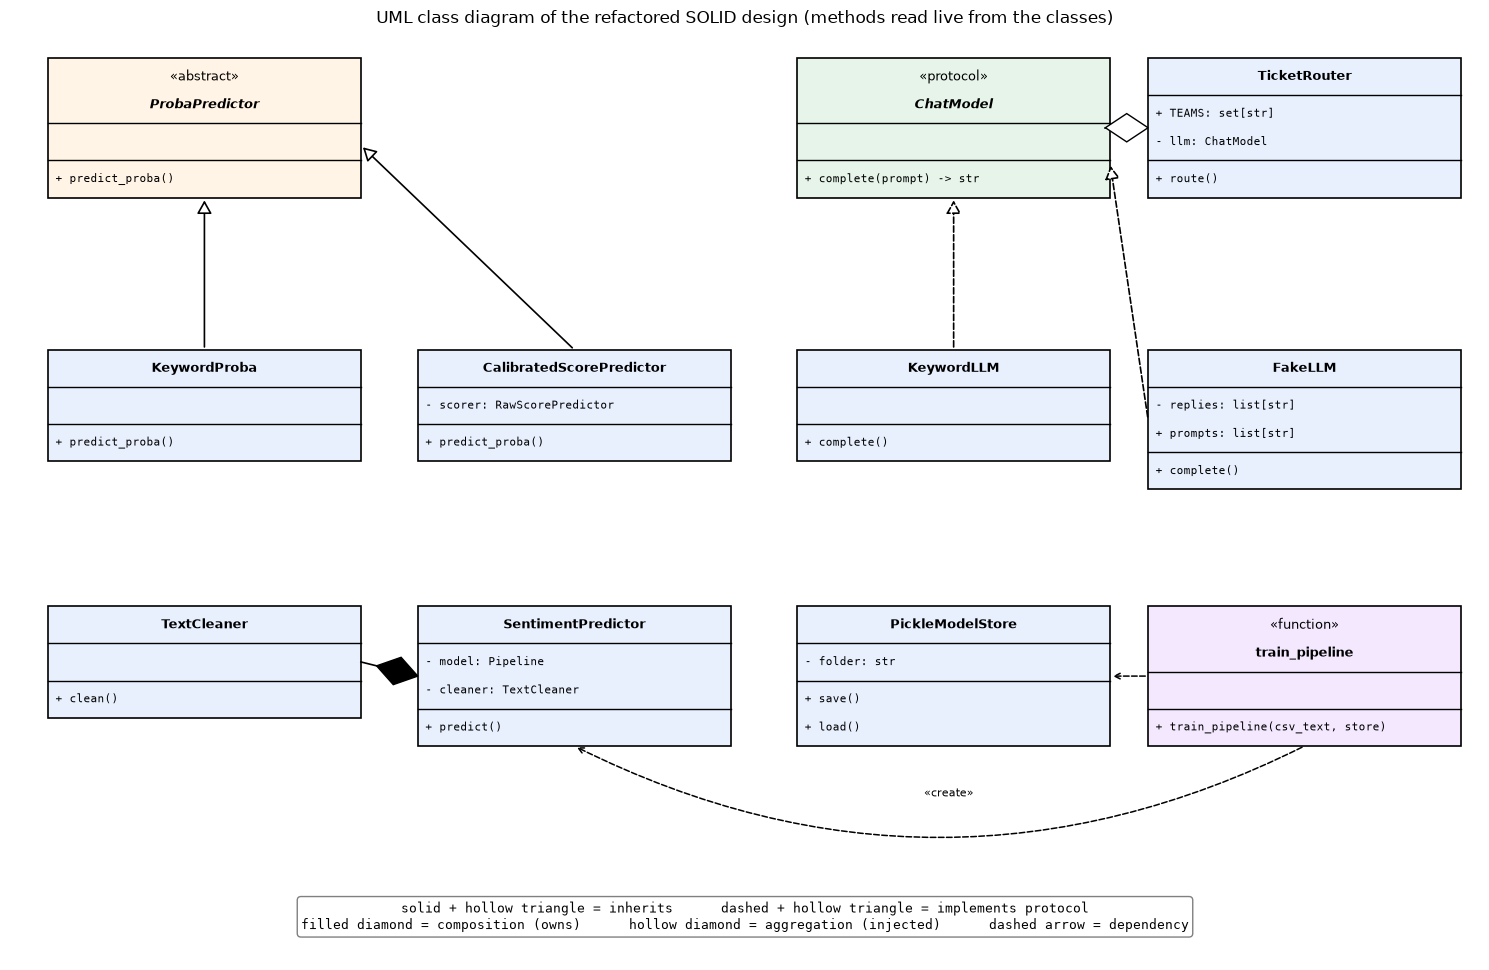

In [37]:
from matplotlib.patches import FancyBboxPatch, Polygon

def public_methods(cls):
    """Methods defined directly on cls (not inherited), excluding private ones; read live."""
    return [f"+ {n}()" for n, v in vars(cls).items() if callable(v) and not n.startswith("_")]

BOX_W, LINE_H = 3.3, 0.32

def draw_class(ax, x, y, name, attrs, methods, stereotype=None, color="#e8f0fe"):
    """Draw a 3-compartment UML class box with its top-left corner at (x, y). Returns its geometry."""
    header = ([f"«{stereotype}»"] if stereotype else []) + [name]
    h_head, h_attr, h_meth = LINE_H * len(header) + 0.1, LINE_H * max(1, len(attrs)) + 0.1, LINE_H * max(1, len(methods)) + 0.1
    total = h_head + h_attr + h_meth
    ax.add_patch(FancyBboxPatch((x, y - total), BOX_W, total, boxstyle="square,pad=0", fc=color, ec="black", lw=1.2))
    for yy in (y - h_head, y - h_head - h_attr):                       # compartment separators
        ax.plot([x, x + BOX_W], [yy, yy], color="black", lw=1)
    for i, line in enumerate(header):
        ax.text(x + BOX_W / 2, y - 0.05 - LINE_H * (i + 0.5), line, ha="center", va="center",
                fontsize=9, fontweight="bold" if line == name else "normal",
                fontstyle="italic" if stereotype in ("abstract", "protocol") and line == name else "normal")
    for i, line in enumerate(attrs):
        ax.text(x + 0.08, y - h_head - 0.05 - LINE_H * (i + 0.5), line, va="center", fontsize=8, family="monospace")
    for i, line in enumerate(methods):
        ax.text(x + 0.08, y - h_head - h_attr - 0.05 - LINE_H * (i + 0.5), line, va="center", fontsize=8, family="monospace")
    return {"top": (x + BOX_W / 2, y), "bottom": (x + BOX_W / 2, y - total),
            "left": (x, y - total / 2), "right": (x + BOX_W, y - total / 2)}

def connect(ax, start, end, kind):
    """Draw a UML relationship from `start` (the 'child'/'whole' side) to `end`."""
    (x0, y0), (x1, y1) = start, end
    dashed = kind in ("realisation", "dependency")
    if kind in ("generalisation", "realisation"):          # hollow triangle at `end`
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="-|>,head_length=0.8,head_width=0.45",
                    fc="white", ec="black", lw=1.2, ls="--" if dashed else "-"))
    elif kind == "dependency":                              # open arrow at `end`
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", ec="black", lw=1.1, ls="--"))
    else:                                                   # composition / aggregation: diamond at `start`
        d = np.array([x1 - x0, y1 - y0]); d = d / np.linalg.norm(d); n = np.array([-d[1], d[0]])
        p0 = np.array(start); L, W = 0.45, 0.16
        diamond = [p0, p0 + d * L / 2 + n * W, p0 + d * L, p0 + d * L / 2 - n * W]
        ax.add_patch(Polygon(diamond, closed=True, fc="black" if kind == "composition" else "white", ec="black", zorder=3))
        ax.plot([p0[0] + d[0] * L, x1], [p0[1] + d[1] * L, y1], color="black", lw=1.2)

fig, ax = plt.subplots(figsize=(15, 9.8))
ax.set_xlim(0, 15.5); ax.set_ylim(-0.9, 9.6); ax.axis("off")

proba = draw_class(ax, 0.4, 9.3, "ProbaPredictor", [], public_methods(ProbaPredictor), "abstract", "#fff4e5")
kw    = draw_class(ax, 0.4, 6.0, "KeywordProba", [], public_methods(KeywordProba))
calib = draw_class(ax, 4.3, 6.0, "CalibratedScorePredictor", ["- scorer: RawScorePredictor"], public_methods(CalibratedScorePredictor))
chat  = draw_class(ax, 8.3, 9.3, "ChatModel", [], ["+ complete(prompt) -> str"], "protocol", "#e6f4ea")
kwllm = draw_class(ax, 8.3, 6.0, "KeywordLLM", [], public_methods(KeywordLLM))
fake  = draw_class(ax, 12.0, 6.0, "FakeLLM", ["- replies: list[str]", "+ prompts: list[str]"], public_methods(FakeLLM))
router= draw_class(ax, 12.0, 9.3, "TicketRouter", ["+ TEAMS: set[str]", "- llm: ChatModel"], public_methods(TicketRouter))
pred  = draw_class(ax, 4.3, 3.1, "SentimentPredictor", ["- model: Pipeline", "- cleaner: TextCleaner"], public_methods(SentimentPredictor))
clean = draw_class(ax, 0.4, 3.1, "TextCleaner", [], public_methods(TextCleaner))
store = draw_class(ax, 8.3, 3.1, "PickleModelStore", ["- folder: str"], public_methods(PickleModelStore))
usecase = draw_class(ax, 12.0, 3.1, "train_pipeline", [], ["+ train_pipeline(csv_text, store)"], "function", "#f3e8fd")

connect(ax, kw["top"], proba["bottom"], "generalisation")
connect(ax, calib["top"], (proba["right"][0], proba["right"][1] - 0.2), "generalisation")
connect(ax, kwllm["top"], chat["bottom"], "realisation")
connect(ax, fake["left"], (chat["right"][0], chat["right"][1] - 0.4), "realisation")
connect(ax, router["left"], chat["right"], "aggregation")
connect(ax, pred["left"], clean["right"], "composition")
connect(ax, usecase["left"], store["right"], "dependency")                     # uses the store
ax.annotate("", xy=pred["bottom"], xytext=usecase["bottom"],                    # «create» dependency
            arrowprops=dict(arrowstyle="->", ec="black", lw=1.1, ls="--", connectionstyle="arc3,rad=-0.25"))
ax.text(9.9, 0.95, "«create»", fontsize=8, ha="center")
ax.set_title("UML class diagram of the refactored SOLID design (methods read live from the classes)", fontsize=12)
legend = ("solid + hollow triangle = inherits      dashed + hollow triangle = implements protocol\n"
          "filled diamond = composition (owns)      hollow diamond = aggregation (injected)      dashed arrow = dependency")
ax.text(7.75, -0.55, legend, ha="center", fontsize=9, family="monospace",
        bbox=dict(boxstyle="round", fc="white", ec="gray"))
plt.tight_layout()
plt.show()
import shutil
shutil.rmtree(tmp_dir)                                    # clean up the temp folder from section 9.1

**How to read it.** `KeywordProba` and `CalibratedScorePredictor` *inherit* from the abstract `ProbaPredictor` (solid lines, hollow triangles). `KeywordLLM` and `FakeLLM` *implement* the `ChatModel` protocol without inheriting from it (dashed lines). `TicketRouter` holds an injected `ChatModel` (hollow diamond: the client lives on its own), while `SentimentPredictor` owns its `TextCleaner` (filled diamond). The `train_pipeline` function (drawn with a «function» stereotype) only *uses* the store and *creates* the predictor: dashed dependency arrows. Abstract and protocol names are in italics, as UML recommends.

> 🎓 **Exam / interview tip:** in a low-level design (LLD) interview, sketch exactly this: interfaces at the top, implementations below, arrows pointing **towards abstractions**. If an arrow points from a high-level policy class to a concrete vendor class, you have found a DIP violation. See [22_ML_System_Design/02_lld_ml_components.ipynb](../22_ML_System_Design/02_lld_ml_components.ipynb).

---
## 13. 🔗 How this connects to modern AI

> 💡 **In plain English:** the AI libraries you use every day are built from exactly these ideas.

| Idea from this notebook | Where you meet it in AI libraries |
|---|---|
| Duck typing + conventions | **scikit-learn**'s estimator API: anything with `fit`/`predict`/`transform` works in a `Pipeline`. `BaseEstimator.get_params()` introspects `__init__`'s signature, which is why sklearn asks you to store every `__init__` argument unchanged. |
| Mixins + MRO | sklearn's `ClassifierMixin`, `TransformerMixin` (you saw them in `LogisticRegression.__mro__`); Django/DRF mixins in web backends |
| Dunder methods | **PyTorch** `nn.Module.__call__` runs hooks and then your `forward()`; `__setattr__` auto-registers parameters; `Dataset` needs `__len__` and `__getitem__`; LangChain's `Runnable` overloads `|` via `__or__` to build chains |
| Class methods as constructors | **Hugging Face** `AutoModel.from_pretrained(...)`, `AutoTokenizer.from_pretrained(...)`; `pd.DataFrame.from_dict` |
| Protocols / ISP | `collections.abc` (`Iterable`, `Sized`...), LangChain's small `invoke`/`batch`/`stream` interface, MCP tool schemas |
| DIP + injection | swapping LLM providers behind one interface (LLM gateways), FastAPI's `Depends` (see [12_FastAPI/02_advanced_fastapi.ipynb](../12_FastAPI/02_advanced_fastapi.ipynb)) |
| Frozen dataclasses / value objects | configs and experiment keys; pydantic models for validated LLM JSON output ([08_LLM/17_structured_outputs.ipynb](../08_LLM/17_structured_outputs.ipynb)) |
| SRP, DRY | splitting data/feature/training/serving code; one shared feature pipeline to prevent training/serving skew ([22_ML_System_Design/07](../22_ML_System_Design/07_software_engineering_for_ml.ipynb)) |

Further practice in the repo: [08_LLM/20_industry_llm_application_patterns.ipynb](../08_LLM/20_industry_llm_application_patterns.ipynb) (provider abstractions in a real app), [05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb](../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb) (classes for a training pipeline).

---
## 14. Recap

- A **class** is a blueprint, an **object** an instance; attribute lookup goes instance → class → bases (MRO). Never use a mutable **class** attribute as per-object state.
- **Encapsulation** in Python = conventions (`_x`), **name mangling** (`__x` → `_Class__x`, prevents subclass clashes, not security) and **properties** (validation without changing callers).
- **Favour composition over inheritance**: n independent features need n parts, not 2^n − 1 subclasses.
- **Duck typing** gives polymorphism without inheritance; **ABCs** (nominal, enforced at instantiation, share code) vs. **Protocols** (structural, checked statically; `runtime_checkable` checks names only).
- Dunders plug your objects into Python's syntax. Keep the **`__eq__`/`__hash__` contract**: equal objects have equal hashes; mutable objects should be unhashable.
- **Dataclasses**: `frozen=True` for hashable value objects, `slots=True` for memory and typo safety, `default_factory` for mutable defaults. **Enums** replace magic strings.
- `@classmethod` = alternative constructors that respect subclasses; `@staticmethod` = namespaced helper.
- The **MRO** comes from **C3 linearization**; `super()` means "next in the MRO", so diamonds call each class once.
- **SOLID**: one reason to change; extend without editing; honour the base contract; small interfaces; depend on abstractions and inject them.
- **DRY** (knowledge, not lines; training/serving skew), **KISS**, **YAGNI**, **law of Demeter**; recognise **code smells** and apply named refactorings.
- **UML**: hollow triangle = inheritance/realisation, diamonds = composition (filled) / aggregation (hollow), dashed arrow = dependency.

## Practice problems

**1. (Easy, conceptual)** Inside `class Layer`, you write `self.__w = 0.5`. What is the attribute really called, and why does Python do this?

<details><summary>Show solution</summary>

It is stored as `_Layer__w` (name mangling). The purpose is to stop a **subclass** from accidentally overwriting it with its own `__w` (which becomes `_SubClass__w`). It is not a privacy or security feature: `obj._Layer__w` still works.
</details>

**2. (Easy, conceptual)** A `BaseRetriever.search(query, k)` promises to work for any `k >= 1`. A subclass `FastRetriever` raises `ValueError` when `k > 5`. Which SOLID principle is violated, and how would you fix it?

<details><summary>Show solution</summary>

**Liskov substitution**: the subclass **strengthens a precondition** (it demands `k <= 5`), so code written against `BaseRetriever` breaks when handed a `FastRetriever`. Fixes: make it honour the contract (e.g. fetch in several rounds of 5, or fall back to a slower path for large `k`), or, if the limit is real, don't make it a subtype: give it a different interface (`TopFiveRetriever`) so callers know.
</details>

**3. (Medium, coding)** Write a frozen, slotted dataclass `Embedding` with fields `vector: tuple` and `model: str`. Validate in `__post_init__` that the vector is not empty, add a `dim` property and a `cosine(other)` method that raises `ValueError` if the two embeddings come from different models. Check that equal embeddings deduplicate in a `set`.

<details><summary>Show solution</summary>

```python
from dataclasses import dataclass
import math

@dataclass(frozen=True, slots=True)
class Embedding:
    vector: tuple
    model: str

    def __post_init__(self):
        if len(self.vector) == 0:
            raise ValueError("empty vector")

    @property
    def dim(self):
        return len(self.vector)

    def cosine(self, other):
        if other.model != self.model:
            raise ValueError("embeddings from different models are not comparable")
        dot = sum(a * b for a, b in zip(self.vector, other.vector))
        norm = math.sqrt(sum(a * a for a in self.vector)) * math.sqrt(sum(b * b for b in other.vector))
        return dot / norm

e1, e2 = Embedding((1.0, 0.0), "m"), Embedding((1.0, 1.0), "m")
assert e1.dim == 2 and abs(e1.cosine(e2) - 1 / math.sqrt(2)) < 1e-12
assert len({e1, Embedding((1.0, 0.0), "m")}) == 1          # hashable value object
try:
    e1.cosine(Embedding((1.0, 0.0), "other")); raise AssertionError
except ValueError:
    pass
```
Because it is `frozen` with the default `eq=True`, the dataclass gets a field-based `__hash__`, so equal embeddings collapse in a set. Comparing vectors from different embedding models is a real bug in RAG systems; refusing it in the type is cheap insurance.
</details>

**4. (Medium, coding)** Write a `BatchIterator(items, batch_size)` that supports `len()` (number of batches) and `for batch in ...` (the last batch may be smaller), and can be iterated more than once.

<details><summary>Show solution</summary>

```python
import math

class BatchIterator:
    def __init__(self, items, batch_size):
        if batch_size < 1:
            raise ValueError("batch_size must be >= 1")
        self.items, self.batch_size = list(items), batch_size

    def __len__(self):                     # number of batches
        return math.ceil(len(self.items) / self.batch_size)

    def __iter__(self):                    # a fresh generator each time: re-iterable
        for start in range(0, len(self.items), self.batch_size):
            yield self.items[start:start + self.batch_size]

b = BatchIterator(range(10), 4)
assert len(b) == 3 and list(b) == [[0, 1, 2, 3], [4, 5, 6, 7], [8, 9]]
assert list(b) == list(b)                  # can iterate twice
assert len(BatchIterator([], 4)) == 0
```
Making `__iter__` a generator function returns a **new** iterator on every `for` loop, so the object is *re-iterable*. If `__iter__` returned `self` and you kept a position counter, the second loop would be empty: a common bug in hand-written data loaders.
</details>

**5. (Medium, exam-style)** Compute the MRO by hand with C3, then check in Python:
```python
class A: pass
class B(A): pass
class C(A): pass
class D(B, C): pass
class E(C): pass
class F(D, E): pass
```

<details><summary>Show solution</summary>

L[D] = D B C A O, L[E] = E C A O. L[F] = F + merge([D B C A O], [E C A O], [D E]).
Take D (not in any tail) → F D. Lists: [B C A O], [E C A O], [E]. Take B → F D B. Lists: [C A O], [E C A O], [E]. C is in the tail of [E C A O], so skip it; take E → F D B E. Then C, A, O.
**MRO = F, D, B, E, C, A, object.**
```python
class A: pass
class B(A): pass
class C(A): pass
class D(B, C): pass
class E(C): pass
class F(D, E): pass
assert [k.__name__ for k in F.__mro__] == ["F", "D", "B", "E", "C", "A", "object"]
```
</details>

**6. (Medium, coding)** This class violates DIP. Refactor it so it can be unit-tested offline, then write the test.
```python
class Summarizer:
    def __init__(self):
        self.llm = RemoteLLM(api_key=os.environ["KEY"])
    def summarize(self, text):
        return self.llm.complete("Summarise: " + text)
```

<details><summary>Show solution</summary>

```python
from typing import Protocol

class ChatModel(Protocol):
    def complete(self, prompt: str) -> str: ...

class Summarizer:
    def __init__(self, llm: ChatModel, max_words: int = 20):
        self.llm, self.max_words = llm, max_words

    def summarize(self, text: str) -> str:
        reply = self.llm.complete(f"Summarise in at most {self.max_words} words:\n{text}")
        words = reply.split()
        return " ".join(words[: self.max_words])          # enforce the limit ourselves

class FakeLLM:
    def __init__(self, reply):
        self.reply, self.prompts = reply, []
    def complete(self, prompt):
        self.prompts.append(prompt)
        return self.reply

fake = FakeLLM("one two three four five")
s = Summarizer(fake, max_words=3)
assert s.summarize("long text") == "one two three"
assert "at most 3 words" in fake.prompts[0] and "long text" in fake.prompts[0]
```
The high-level `Summarizer` depends only on the `ChatModel` protocol. The fake records prompts, so the test can check the prompt *and* the post-processing (enforcing the word limit even if the LLM ignores it).
</details>

**7. (Hard, coding)** Implement an `LRUCache(capacity)` for caching embeddings, with `cache[key] = value`, `cache[key]`, `key in cache` and `len(cache)`. All operations must be O(1), and the least recently *used* key is evicted when full.

<details><summary>Show solution</summary>

```python
from collections import OrderedDict

class LRUCache:
    """Fixed-capacity cache that evicts the least recently used key. All operations O(1)."""
    def __init__(self, capacity):
        if capacity < 1:
            raise ValueError("capacity must be >= 1")
        self.capacity, self._data = capacity, OrderedDict()

    def __len__(self):
        return len(self._data)

    def __contains__(self, key):            # membership test does NOT count as a use
        return key in self._data

    def __getitem__(self, key):
        value = self._data[key]             # KeyError if missing, like a dict
        self._data.move_to_end(key)         # mark as most recently used
        return value

    def __setitem__(self, key, value):
        if key in self._data:
            self._data.move_to_end(key)
        self._data[key] = value
        if len(self._data) > self.capacity:
            self._data.popitem(last=False)  # evict the least recently used (front)

    def __repr__(self):
        return f"LRUCache(capacity={self.capacity}, keys={list(self._data)})"

c = LRUCache(2)
c["a"] = [0.1]; c["b"] = [0.2]
_ = c["a"]                                  # "a" is now most recent
c["c"] = [0.3]                              # evicts "b"
assert "b" not in c and "a" in c and "c" in c and len(c) == 2
```
`OrderedDict` is a hash map plus a doubly linked list, so `move_to_end` and `popitem(last=False)` are O(1). In everyday code, `functools.lru_cache` does this for function results.
</details>

**8. (Hard, design)** You inherit a `ModelManager` class with these methods: `load_csv`, `clean_text`, `train`, `evaluate`, `save_to_s3`, `predict`, `explain`, `send_slack_alert`. Propose a refactoring: which classes or protocols would you create, which SOLID principles motivate each split, and what would the composition root look like?

<details><summary>Show solution</summary>

One possible answer: `DataLoader` (load_csv), `TextCleaner` (clean_text), `Trainer` (train), `Evaluator` (evaluate), `ModelStore` protocol with `S3ModelStore` and `LocalModelStore` (save/load), `Predictor` (predict) and an optional `Explainable` protocol (explain), and a `Notifier` protocol with `SlackNotifier`. SRP motivates the split (each has a different reason to change: data team, ML team, platform team, on-call). DIP and ISP motivate the protocols (`ModelStore`, `Notifier`, `Explainable`), so tests can use in-memory fakes and models that can't explain aren't forced to. OCP: new stores or notifiers are added without editing the trainer. The composition root, e.g. `main()`, builds `Trainer(...)`, `S3ModelStore(bucket)`, `SlackNotifier(webhook)` from config and passes them into a small `TrainingJob(loader, cleaner, trainer, evaluator, store, notifier).run()`.
</details>

## Further reading

- Robert C. Martin, *Clean Architecture* (2017), Part III "Design Principles", chapters 7-11 (one chapter per SOLID principle). Also *Agile Software Development: Principles, Patterns, and Practices* (2002).
- Martin Fowler, *Refactoring*, 2nd ed. (2018), chapter 3 "Bad Smells in Code" (with Kent Beck) and the catalogue of refactorings.
- Luciano Ramalho, *Fluent Python*, 2nd ed. (2022): ch. 1 (the data model), ch. 5 (data class builders), ch. 13 (interfaces, protocols and ABCs), ch. 14 (inheritance, MRO and mixins).
- Andrew Hunt and David Thomas, *The Pragmatic Programmer*, 20th anniversary ed. (2019): DRY, orthogonality, decoupling and the law of Demeter.
- Barbara Liskov and Jeannette Wing, "A Behavioral Notion of Subtyping", *ACM TOPLAS* (1994).
- Free online: the Python **Data model** reference (docs.python.org/3/reference/datamodel.html), "The Python 2.3 Method Resolution Order" by Michele Simionato (docs.python.org/3/howto/mro.html), PEP 544 (Protocols) and PEP 557 (dataclasses), and refactoring.guru (catalogue of smells and refactorings).

## Next notebook

➡️ [02_design_patterns_for_ai_code.ipynb](02_design_patterns_for_ai_code.ipynb): factories, adapters for LLM SDKs, retry/caching decorators, observers for training callbacks, guardrail chains and more, each with when **not** to use it.